In [3]:
# Import Google Earth Engine
import ee

# Sign in to Google Earth Engine
ee.Authenticate()

In [5]:
import ee

ee.Initialize(project="china-turkiye-urban")

print("Earth Engine connection successful!")

Earth Engine connection successful!


In [6]:
# Check WorldPop population data
worldpop = (
    ee.ImageCollection("WorldPop/GP/100m/pop")
    .filterDate("2001-01-01", "2002-01-01")
)

# Check MODIS land-cover data
modis = (
    ee.ImageCollection("MODIS/061/MCD12Q1")
    .filterDate("2001-01-01", "2002-01-01")
)

print("WorldPop image count:", worldpop.size().getInfo())
print("MODIS image count:", modis.size().getInfo())

WorldPop image count: 249
MODIS image count: 1


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os

base_path = "/content/drive/MyDrive"

print("Drive içindeki klasörler:")
print(os.listdir(base_path))

Drive içindeki klasörler:
['Classroom', 'Belge 1.rtf.gdoc', 'Matematik..zip', 'ödev.mp4', 'Podcast', '600 Russian phrases_копия.pdf', 'rusçab1.pdf', 'DOC-20251030-WA0053..xlsx', 'Başlıksız e-tablo.gsheet', 'YeniSponsorlukDosyası.xlsx', 'russian.pdf', 'lovely docus with mert.gdoc', 'lovely docus with mert.docx', 'Colab Notebooks', 'Urban_Heat_Transfer_COMPLETE_BUNDLE', 'phase2_outputs', 'docs', 'external_features', 'ndvi_import_bundle.zip']


In [ ]:
import os

search_roots = [
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE",
    "/content/drive/MyDrive/phase2_outputs"
]

for root in search_roots:
    print(f"\n--- {root} ---")

    if os.path.exists(root):
        for current_root, dirs, files in os.walk(root):
            if "task6_feature_matrix.csv" in files:
                print("File found:")
                print(os.path.join(current_root, "task6_feature_matrix.csv"))
    else:
        print("This folder was not found.")


--- /content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE ---
DOSYA BULUNDU:
/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/archive/historical_artifacts/Urban_Heat_Transfer_History_Archive_Not_For_GitHub/legacy_outputs_and_audits/legacy_tao_phase2_outputs/task6_feature_matrix.csv
DOSYA BULUNDU:
/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/phase2_outputs/task6_feature_matrix.csv

--- /content/drive/MyDrive/phase2_outputs ---


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/phase2_outputs/task6_feature_matrix.csv"
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (32420, 9)

Column names:
['UrbanId', 'year', 'Intensity_MEA', 'Country', 'source_file', 'Longitude', 'Latitude', 'Area', 'area_log']

First 5 rows:


,UrbanId,year,Intensity_MEA,Country,source_file,Longitude,Latitude,Area,area_log
0,5,2001,0.266515,China,Mod2_Nig_2001_22.csv,120.865712,31.425684,6873.482734,8.835426
1,5,2002,0.354056,China,Mod2_Nig_2002_22.csv,120.865712,31.425684,6873.482734,8.835426
2,5,2003,0.127355,China,Mod2_Nig_2003_22.csv,120.865712,31.425684,6873.482734,8.835426
3,5,2004,0.385441,China,Mod2_Nig_2004_22.csv,120.865712,31.425684,6873.482734,8.835426
4,5,2005,0.528123,China,Mod2_Nig_2005_22.csv,120.865712,31.425684,6873.482734,8.835426


In [ ]:
# Check the spatial and temporal coverage of the dataset

print("Number of unique cities:", df["UrbanId"].nunique())

print("\nYears covered:")
print(df["year"].min(), "-", df["year"].max())

print("\nCities by country:")
print(df.groupby("Country")["UrbanId"].nunique())

print("\nMissing coordinates:")
print(df[["Longitude", "Latitude"]].isna().sum())

print("\nUnique city coordinates:")
print(
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
    .shape
)

Number of unique cities: 1621

Years covered:
2001 - 2020

Cities by country:
Country
China      1441
Türkiye     180
Name: UrbanId, dtype: int64

Missing coordinates:
Longitude    0
Latitude     0
dtype: int64

Unique city coordinates:
(1621, 4)


In [ ]:
# Inspect WorldPop data for 2001
worldpop_2001 = ee.ImageCollection(
    "WorldPop/GP/100m/pop"
).filterDate("2001-01-01", "2002-01-01")

print("Number of images:", worldpop_2001.size().getInfo())

# Inspect the first image
worldpop_image = ee.Image(worldpop_2001.first())

print("Image bands:", worldpop_image.bandNames().getInfo())
print("Image date:", ee.Date(worldpop_image.get("system:time_start")).format("YYYY-MM-dd").getInfo())
print("Image properties:", worldpop_image.propertyNames().getInfo())

Number of images: 249
Image bands: ['population']
Image date: 2001-01-01
Image properties: ['system:time_start', 'country', 'year', 'system:footprint', 'system:time_end', 'system:version', 'system:id', 'system:asset_size', 'system:index', 'system:bands', 'system:band_names']


In [ ]:
# List the countries available in the 2001 WorldPop collection

worldpop_2001 = ee.ImageCollection(
    "WorldPop/GP/100m/pop"
).filterDate("2001-01-01", "2002-01-01")

countries_2001 = (
    worldpop_2001
    .aggregate_array("country")
    .distinct()
    .sort()
    .getInfo()
)

print("Number of country entries:", len(countries_2001))
print(countries_2001)

Number of country entries: 249
['ABW', 'AFG', 'AGO', 'AIA', 'ALA', 'ALB', 'AND', 'ARE', 'ARG', 'ARM', 'ASM', 'ATA', 'ATF', 'ATG', 'AUS', 'AUT', 'AZE', 'BDI', 'BEL', 'BEN', 'BES', 'BFA', 'BGD', 'BGR', 'BHR', 'BHS', 'BIH', 'BLM', 'BLR', 'BLZ', 'BMU', 'BOL', 'BRA', 'BRB', 'BRN', 'BTN', 'BVT', 'BWA', 'CAF', 'CAN', 'CHE', 'CHL', 'CHN', 'CIV', 'CMR', 'COD', 'COG', 'COK', 'COL', 'COM', 'CPV', 'CRI', 'CUB', 'CUW', 'CYM', 'CYP', 'CZE', 'DEU', 'DJI', 'DMA', 'DNK', 'DOM', 'DZA', 'ECU', 'EGY', 'ERI', 'ESH', 'ESP', 'EST', 'ETH', 'FIN', 'FJI', 'FLK', 'FRA', 'FRO', 'FSM', 'GAB', 'GBR', 'GEO', 'GGY', 'GHA', 'GIB', 'GIN', 'GLP', 'GMB', 'GNB', 'GNQ', 'GRC', 'GRD', 'GRL', 'GTM', 'GUF', 'GUM', 'GUY', 'HKG', 'HMD', 'HND', 'HRV', 'HTI', 'HUN', 'IDN', 'IMN', 'IND', 'IOT', 'IRL', 'IRN', 'IRQ', 'ISL', 'ISR', 'ITA', 'JAM', 'JEY', 'JOR', 'JPN', 'KAZ', 'KEN', 'KGZ', 'KHM', 'KIR', 'KNA', 'KOR', 'KOS', 'KWT', 'LAO', 'LBN', 'LBR', 'LBY', 'LCA', 'LIE', 'LKA', 'LSO', 'LTU', 'LUX', 'LVA', 'MAC', 'MAF', 'MAR', 'MCO', 'M

In [ ]:
# Check WorldPop availability for China and Türkiye, 2001–2020

for year in range(2001, 2021):
    yearly_data = ee.ImageCollection(
        "WorldPop/GP/100m/pop"
    ).filterDate(
        f"{year}-01-01",
        f"{year + 1}-01-01"
    )

    china_count = yearly_data.filter(
        ee.Filter.eq("country", "CHN")
    ).size().getInfo()

    turkey_count = yearly_data.filter(
        ee.Filter.eq("country", "TUR")
    ).size().getInfo()

    print(
        f"{year}: China = {china_count}, Türkiye = {turkey_count}"
    )

2001: China = 1, Türkiye = 1
2002: China = 1, Türkiye = 1
2003: China = 1, Türkiye = 1
2004: China = 1, Türkiye = 1
2005: China = 1, Türkiye = 1
2006: China = 1, Türkiye = 1
2007: China = 1, Türkiye = 1
2008: China = 1, Türkiye = 1
2009: China = 1, Türkiye = 1
2010: China = 1, Türkiye = 1
2011: China = 1, Türkiye = 1
2012: China = 1, Türkiye = 1
2013: China = 1, Türkiye = 1
2014: China = 1, Türkiye = 1
2015: China = 1, Türkiye = 1
2016: China = 1, Türkiye = 1
2017: China = 1, Türkiye = 1
2018: China = 1, Türkiye = 1
2019: China = 1, Türkiye = 1
2020: China = 1, Türkiye = 1


In [ ]:
# Test population extraction for 5 cities from each country

import pandas as pd
import ee

# Get one row per city
cities = (
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
)

# Select 5 cities from each country
test_cities = (
    cities.groupby("Country", group_keys=False)
    .head(5)
)

results = []

# Extract population values for each country
for country_name, country_code in [
    ("China", "CHN"),
    ("Türkiye", "TUR")
]:
    country_cities = test_cities[
        test_cities["Country"] == country_name
    ]

    # Convert city coordinates into Earth Engine points
    features = []

    for _, row in country_cities.iterrows():
        point = ee.Geometry.Point([
            float(row["Longitude"]),
            float(row["Latitude"])
        ])

        feature = ee.Feature(
            point,
            {
                "UrbanId": int(row["UrbanId"]),
                "Country": country_name
            }
        )

        features.append(feature)

    city_points = ee.FeatureCollection(features)

    # Select the correct country's WorldPop image for 2001
    population_image = (
        ee.ImageCollection("WorldPop/GP/100m/pop")
        .filterDate("2001-01-01", "2002-01-01")
        .filter(ee.Filter.eq("country", country_code))
        .first()
        .select("population")
    )

    # Sample the population pixel at each city coordinate
    sampled = population_image.sampleRegions(
        collection=city_points,
        properties=["UrbanId", "Country"],
        scale=100,
        geometries=False
    )

    sampled_data = sampled.getInfo()

    for feature in sampled_data["features"]:
        results.append(feature["properties"])

# Display the test results
population_test = pd.DataFrame(results)

print("Cities selected:", len(test_cities))
print("Cities with population values:", len(population_test))
print("\nResults:")
display(population_test)

Cities selected: 10
Cities with population values: 10

Results:


,Country,UrbanId,population
0,China,5,3.669293
1,China,9,389.014069
2,China,12,27.429760
3,China,19,2.065371
4,China,21,0.835929
5,Türkiye,179,12.550558
6,Türkiye,261,48.101746
7,Türkiye,483,6.333916
8,Türkiye,503,55.286232
9,Türkiye,605,14.152693


In [ ]:
# Test WorldPop coverage for all cities in 2001

cities = (
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
)

results_2001 = []

for country_name, country_code in [
    ("China", "CHN"),
    ("Türkiye", "TUR")
]:
    country_cities = cities[
        cities["Country"] == country_name
    ]

    # Create Earth Engine points for the selected cities
    features = []

    for _, row in country_cities.iterrows():
        point = ee.Geometry.Point([
            float(row["Longitude"]),
            float(row["Latitude"])
        ])

        features.append(
            ee.Feature(
                point,
                {
                    "UrbanId": int(row["UrbanId"]),
                    "Country": country_name
                }
            )
        )

    city_points = ee.FeatureCollection(features)

    # Select the country-specific population image for 2001
    image = (
        ee.ImageCollection("WorldPop/GP/100m/pop")
        .filterDate("2001-01-01", "2002-01-01")
        .filter(ee.Filter.eq("country", country_code))
        .first()
        .select("population")
    )

    # Sample population values at the city coordinates
    sampled = image.sampleRegions(
        collection=city_points,
        properties=["UrbanId", "Country"],
        scale=100,
        geometries=False
    )

    results_2001.extend(
        feature["properties"]
        for feature in sampled.getInfo()["features"]
    )

population_2001 = pd.DataFrame(results_2001)

print("Expected cities:", len(cities))
print("Cities with sampled values:", len(population_2001))
print("Unique cities sampled:", population_2001["UrbanId"].nunique())
print("\nResults by country:")
print(population_2001.groupby("Country")["population"].agg(
    ["count", "min", "median", "max"]
))
print("\nMissing population values:", population_2001["population"].isna().sum())

Expected cities: 1621
Cities with sampled values: 1570
Unique cities sampled: 1570

Results by country:
         count       min     median         max
Country                                        
China     1392  0.029812  25.621375  502.383759
Türkiye    178  0.241774  14.171007   98.118706

Missing population values: 0


In [ ]:
# Identify cities that did not return WorldPop values

sampled_cities = population_2001[
    ["UrbanId", "Country"]
].drop_duplicates()

coverage_check = cities.merge(
    sampled_cities,
    on=["UrbanId", "Country"],
    how="left",
    indicator=True
)

missing_cities = coverage_check.loc[
    coverage_check["_merge"] == "left_only",
    ["UrbanId", "Country", "Longitude", "Latitude"]
]

print("Missing cities:", len(missing_cities))

print("\nMissing cities by country:")
print(missing_cities["Country"].value_counts())

print("\nCity coordinates:")
display(missing_cities)

Missing cities: 51

Missing cities by country:
Country
China      49
Türkiye     2
Name: count, dtype: int64

City coordinates:


,UrbanId,Country,Longitude,Latitude
33,197,China,110.180828,22.640567
47,283,China,112.446017,34.657240
72,476,China,119.254579,34.643957
79,525,China,109.395167,24.322073
106,763,China,112.242112,30.322411
120,880,China,113.581710,24.770653
126,907,China,113.129461,27.856743
132,950,China,114.905795,25.810468
134,968,China,124.384177,40.112616
137,998,China,119.643402,29.100338


In [ ]:
# Diagnose the 51 cities missing WorldPop samples in 2001

diagnostic_results = []

for country_name, country_code in [
    ("China", "CHN"),
    ("Türkiye", "TUR")
]:
    country_missing = missing_cities[
        missing_cities["Country"] == country_name
    ]

    # Build points for the missing cities
    features = []

    for _, row in country_missing.iterrows():
        point = ee.Geometry.Point([
            float(row["Longitude"]),
            float(row["Latitude"])
        ])

        features.append(
            ee.Feature(
                point,
                {"UrbanId": int(row["UrbanId"]),
                 "Country": country_name}
            )
        )

    points = ee.FeatureCollection(features)

    # Get the matching WorldPop image for 2001
    image = (
        ee.ImageCollection("WorldPop/GP/100m/pop")
        .filterDate("2001-01-01", "2002-01-01")
        .filter(ee.Filter.eq("country", country_code))
        .first()
        .select("population")
    )

    # Use a sentinel value to reveal masked or uncovered pixels
    diagnostic_image = image.unmask(-9999, False)

    sampled = diagnostic_image.sampleRegions(
        collection=points,
        properties=["UrbanId", "Country"],
        scale=100,
        geometries=False
    )

    diagnostic_results.extend(
        feature["properties"]
        for feature in sampled.getInfo()["features"]
    )

diagnostic_df = pd.DataFrame(diagnostic_results)

print("Expected missing cities:", len(missing_cities))
print("Cities returned by diagnostic:", len(diagnostic_df))
print("\nSampled population values:")
print(diagnostic_df["population"].value_counts().head(10))

print("\nCities with masked/uncovered pixels (-9999):")
print((diagnostic_df["population"] == -9999).sum())

print("\nDiagnostic results:")
display(diagnostic_df)

Expected missing cities: 51
Cities returned by diagnostic: 51

Sampled population values:
population
-9999    51
Name: count, dtype: int64

Cities with masked/uncovered pixels (-9999):
51

Diagnostic results:


,Country,UrbanId,population
0,China,197,-9999
1,China,283,-9999
2,China,476,-9999
3,China,525,-9999
4,China,763,-9999
5,China,880,-9999
6,China,907,-9999
7,China,950,-9999
8,China,968,-9999
9,China,998,-9999


In [ ]:
# Check population data within a 1 km radius of missing city points

buffer_results = []

for country_name, country_code in [
    ("China", "CHN"),
    ("Türkiye", "TUR")
]:
    country_missing = missing_cities[
        missing_cities["Country"] == country_name
    ]

    features = []

    for _, row in country_missing.iterrows():
        point = ee.Geometry.Point([
            float(row["Longitude"]),
            float(row["Latitude"])
        ])

        # Use a 1 km radius around each city coordinate
        features.append(
            ee.Feature(
                point.buffer(1000),
                {
                    "UrbanId": int(row["UrbanId"]),
                    "Country": country_name
                }
            )
        )

    areas = ee.FeatureCollection(features)

    image = (
        ee.ImageCollection("WorldPop/GP/100m/pop")
        .filterDate("2001-01-01", "2002-01-01")
        .filter(ee.Filter.eq("country", country_code))
        .first()
        .select("population")
    )

    # Calculate the mean population value and count valid pixels
    reducer = ee.Reducer.mean().combine(
        reducer2=ee.Reducer.count(),
        sharedInputs=True
    )

    sampled = image.reduceRegions(
        collection=areas,
        reducer=reducer,
        scale=100
    )

    buffer_results.extend(
        feature["properties"]
        for feature in sampled.getInfo()["features"]
    )

buffer_df = pd.DataFrame(buffer_results)

print("Cities checked:", len(buffer_df))
print("\nAvailable columns:")
print(buffer_df.columns.tolist())

print("\nFirst 10 results:")
display(buffer_df.head(10))

Cities checked: 51

Available columns:
['Country', 'UrbanId', 'count', 'mean']

First 10 results:


,Country,UrbanId,count,mean
0,China,197,354,24.554363
1,China,283,321,25.440970
2,China,476,336,7.523624
3,China,525,245,113.452612
4,China,763,347,156.779093
5,China,880,275,37.636391
6,China,907,345,86.145229
7,China,950,341,12.188117
8,China,968,143,95.323147
9,China,998,335,81.589485


In [ ]:
# Check whether all 51 cities have valid pixels in their 1 km buffers

print("Total cities checked:", len(buffer_df))

print(
    "Cities with valid pixels:",
    (buffer_df["count"] > 0).sum()
)

print(
    "Cities with no valid pixels:",
    (buffer_df["count"] == 0).sum()
)

print(
    "Cities with missing mean:",
    buffer_df["mean"].isna().sum()
)

print("\nSummary by country:")
display(
    buffer_df.groupby("Country").agg(
        cities=("UrbanId", "nunique"),
        min_valid_pixels=("count", "min"),
        median_valid_pixels=("count", "median"),
        min_mean=("mean", "min"),
        median_mean=("mean", "median"),
        max_mean=("mean", "max")
    )
)

Total cities checked: 51
Cities with valid pixels: 51
Cities with no valid pixels: 0
Cities with missing mean: 0

Summary by country:


,cities,min_valid_pixels,median_valid_pixels,min_mean,median_mean,max_mean
Country,,,,,,
China,49,92,326.0,0.483093,39.897020,287.084131
Türkiye,2,202,206.5,3.499238,13.958932,24.418627


In [ ]:
# Calculate population within a 1 km radius for all cities in 2001

cities = (
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
)

results = []

for country_name, country_code in [
    ("China", "CHN"),
    ("Türkiye", "TUR")
]:
    country_cities = cities[
        cities["Country"] == country_name
    ]

    # Create a 1 km buffer around each city coordinate
    features = []

    for _, row in country_cities.iterrows():
        point = ee.Geometry.Point([
            float(row["Longitude"]),
            float(row["Latitude"])
        ])

        features.append(
            ee.Feature(
                point.buffer(1000),
                {
                    "UrbanId": int(row["UrbanId"]),
                    "Country": country_name
                }
            )
        )

    city_areas = ee.FeatureCollection(features)

    # Select the matching country's WorldPop image for 2001
    image = (
        ee.ImageCollection("WorldPop/GP/100m/pop")
        .filterDate("2001-01-01", "2002-01-01")
        .filter(ee.Filter.eq("country", country_code))
        .first()
        .select("population")
    )

    # Calculate total population and number of valid pixels
    reducer = ee.Reducer.sum().combine(
        reducer2=ee.Reducer.count(),
        sharedInputs=True
    )

    sampled = image.reduceRegions(
        collection=city_areas,
        reducer=reducer,
        scale=100,
        tileScale=4
    )

    results.extend(
        feature["properties"]
        for feature in sampled.getInfo()["features"]
    )

# Store the results in a separate DataFrame
population_2001_all = pd.DataFrame(results)

print("Expected cities:", len(cities))
print(
    "Cities with results:",
    population_2001_all["UrbanId"].nunique()
)
print("\nOutput columns:")
print(population_2001_all.columns.tolist())

print("\nMissing total population values:",
      population_2001_all["sum"].isna().sum())

print("\nCities with zero valid pixels:",
      (population_2001_all["count"] == 0).sum())

print("\nPopulation summary:")
print(population_2001_all["sum"].describe())

display(population_2001_all.head())

Expected cities: 1621
Cities with results: 1621

Output columns:
['Country', 'UrbanId', 'count', 'sum']

Missing total population values: 0

Cities with zero valid pixels: 0

Population summary:
count      1621.000000
mean      13925.705348
std       13450.677328
min          14.035591
25%        3999.813495
50%       10403.611180
75%       19392.871036
max      130959.378339
Name: sum, dtype: float64


,Country,UrbanId,count,sum
0,China,5,259,1266.301708
1,China,9,449,82248.698567
2,China,12,383,8349.207646
3,China,19,427,905.333200
4,China,21,395,1563.249575


In [ ]:
import os
import pandas as pd
import ee

# Initialize Google Earth Engine
ee.Initialize(project="china-turkiye-urban")

# Define output path
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "worldpop_1km_2001_2020.csv"
)

# Keep one row per city
cities = (
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total unique cities:", len(cities))

# Create a 1 km buffer around each city coordinate
city_features = []

for _, row in cities.iterrows():
    point = ee.Geometry.Point([
        float(row["Longitude"]),
        float(row["Latitude"])
    ])

    city_features.append(
        ee.Feature(
            point.buffer(1000),
            {
                "UrbanId": int(row["UrbanId"]),
                "Country": row["Country"]
            }
        )
    )

all_city_areas = ee.FeatureCollection(city_features)

# Check whether a previous run produced valid results
completed = set()

if os.path.exists(output_path):
    saved = pd.read_csv(output_path)
    saved["year"] = saved["year"].astype(int)

    expected_by_country = (
        cities.groupby("Country")["UrbanId"].nunique().to_dict()
    )

    valid_pairs = []

    for (year, country), group in saved.groupby(["year", "Country"]):
        expected = expected_by_country.get(country, 0)

        if (
            len(group) == expected
            and group["UrbanId"].nunique() == expected
            and group["Population_1km_Sum"].notna().all()
        ):
            valid_pairs.append((int(year), country))

    valid_pair_set = set(valid_pairs)

    saved = saved[
        saved.apply(
            lambda row: (
                int(row["year"]), row["Country"]
            ) in valid_pair_set,
            axis=1
        )
    ]

    if len(saved) > 0:
        saved.to_csv(output_path, index=False)
        completed = valid_pair_set
    elif os.path.exists(output_path):
        os.remove(output_path)

    print("Previously completed country-years:", len(completed))

# Extract data for each year and country
countries = [
    ("China", "CHN"),
    ("Türkiye", "TUR")
]

reducer = ee.Reducer.sum().combine(
    reducer2=ee.Reducer.count(),
    sharedInputs=True
)

for year in range(2001, 2021):
    print(f"\nProcessing year: {year}")

    for country_name, country_code in countries:

        # Skip country-years already saved successfully
        if (year, country_name) in completed:
            print(f"  Skipped {country_name}: already completed")
            continue

        country_areas = all_city_areas.filter(
            ee.Filter.eq("Country", country_name)
        )

        # Load the WorldPop population image for this year
        image = (
            ee.ImageCollection("WorldPop/GP/100m/pop")
            .filterDate(
                f"{year}-01-01",
                f"{year + 1}-01-01"
            )
            .filter(
                ee.Filter.eq("country", country_code)
            )
            .first()
            .select("population")
        )

        # Calculate population sum and valid pixel count
        sampled = image.reduceRegions(
            collection=country_areas,
            reducer=reducer,
            scale=100,
            tileScale=4
        )

        features = sampled.getInfo()["features"]

        records = []

        for feature in features:
            properties = feature["properties"]

            records.append({
                "UrbanId": properties["UrbanId"],
                "Country": properties["Country"],
                "year": year,
                "Population_1km_Sum": properties.get("sum"),
                "Population_1km_ValidPixels": properties.get("count")
            })

        chunk = pd.DataFrame(records)

        expected = cities[
            cities["Country"] == country_name
        ]["UrbanId"].nunique()

        # Validate the output before saving
        if (
            len(chunk) != expected
            or chunk["UrbanId"].nunique() != expected
        ):
            raise ValueError(
                f"Incomplete results for {country_name}, {year}. "
                f"Expected {expected} cities, received "
                f"{chunk['UrbanId'].nunique()} unique cities."
            )

        if (
            chunk["Population_1km_Sum"].isna().any()
            or chunk["Population_1km_ValidPixels"].isna().any()
            or (chunk["Population_1km_ValidPixels"] == 0).any()
        ):
            raise ValueError(
                f"Missing population data for {country_name}, {year}. "
                "The incomplete results were not saved."
            )

        # Save after each country-year to protect completed results
        file_exists = os.path.exists(output_path)

        chunk.to_csv(
            output_path,
            mode="a" if file_exists else "w",
            header=not file_exists,
            index=False
        )

        completed.add((year, country_name))

        print(
            f"  {country_name}: {len(chunk)} cities saved"
        )

print("\nExtraction finished!")
print("Output file:", output_path)

# Validate the final dataset
population_data = pd.read_csv(output_path)

print("\nTotal records:", len(population_data))
print("Unique cities:", population_data["UrbanId"].nunique())
print(
    "Years covered:",
    population_data["year"].min(),
    "-",
    population_data["year"].max()
)
print("\nRecords by year:")
print(population_data.groupby("year").size())

display(population_data.head())

Total unique cities: 1621

Processing year: 2001
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2002
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2003
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2004
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2005
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2006
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2007


  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2008
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2009
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2010
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2011
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2012
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2013
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2014
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2015
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2016
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2017
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2018
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processing year: 2019
  China: 1441 cities saved
  Türkiye: 180 cities saved

Processi

,UrbanId,Country,year,Population_1km_Sum,Population_1km_ValidPixels
0,5,China,2001,1266.301708,259
1,9,China,2001,82248.698567,449
2,12,China,2001,8349.207646,383
3,19,China,2001,905.333200,427
4,21,China,2001,1563.249575,395


In [ ]:
import os
import pandas as pd
import ee

# Initialize Google Earth Engine
ee.Initialize(project="china-turkiye-urban")

# Define the output path
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "modis_landcover_1km_2001_2020.csv"
)

# Keep one row per city
cities = (
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total unique cities:", len(cities))

# Create a 1 km radius around each city
city_features = []

for _, row in cities.iterrows():
    point = ee.Geometry.Point([
        float(row["Longitude"]),
        float(row["Latitude"])
    ])

    city_features.append(
        ee.Feature(
            point.buffer(1000),
            {
                "UrbanId": int(row["UrbanId"]),
                "Country": row["Country"]
            }
        )
    )

city_areas = ee.FeatureCollection(city_features)

# Identify previously completed years
completed_years = set()

if os.path.exists(output_path):
    saved = pd.read_csv(output_path)

    required_columns = {
        "UrbanId",
        "Country",
        "year",
        "LandCover_IGBP_Mode",
        "LandCover_ValidPixels"
    }

    if not required_columns.issubset(saved.columns):
        raise ValueError(
            "The existing output file has unexpected columns. "
            "Please inspect it before continuing."
        )

    saved["year"] = saved["year"].astype(int)

    valid_years = []

    for year, group in saved.groupby("year"):
        if (
            len(group) == len(cities)
            and group["UrbanId"].nunique() == len(cities)
            and group["LandCover_IGBP_Mode"].notna().all()
            and group["LandCover_ValidPixels"].notna().all()
            and (group["LandCover_ValidPixels"] > 0).all()
        ):
            valid_years.append(int(year))

    completed_years = set(valid_years)

    # Keep only fully completed years
    saved = saved[saved["year"].isin(completed_years)]

    if not saved.empty:
        saved.to_csv(output_path, index=False)
    else:
        os.remove(output_path)

    print("Previously completed years:", len(completed_years))

# Prepare the reducer:
# Find the most frequent land-cover class and count valid pixels
reducer = ee.Reducer.mode().combine(
    reducer2=ee.Reducer.count(),
    sharedInputs=True
)

# Process every year from 2001 to 2020
for year in range(2001, 2021):

    if year in completed_years:
        print(f"Skipping {year}: already completed")
        continue

    print(f"\nProcessing year: {year}")

    # Load the annual MODIS land-cover image
    image = (
        ee.ImageCollection("MODIS/061/MCD12Q1")
        .filterDate(
            f"{year}-01-01",
            f"{year + 1}-01-01"
        )
        .first()
        .select("LC_Type1")
    )

    # Calculate the dominant land-cover type in each city buffer
    sampled = image.reduceRegions(
        collection=city_areas,
        reducer=reducer,
        scale=500,
        tileScale=4
    )

    features = sampled.getInfo()["features"]

    records = []

    for feature in features:
        properties = feature["properties"]

        records.append({
            "UrbanId": properties["UrbanId"],
            "Country": properties["Country"],
            "year": year,
            "LandCover_IGBP_Mode": properties.get("mode"),
            "LandCover_ValidPixels": properties.get("count")
        })

    chunk = pd.DataFrame(records)

    # Validate the results before saving
    if (
        len(chunk) != len(cities)
        or chunk["UrbanId"].nunique() != len(cities)
    ):
        raise ValueError(
            f"Incomplete city results for {year}. "
            f"Expected {len(cities)} cities, "
            f"received {chunk['UrbanId'].nunique()}."
        )

    if (
        chunk["LandCover_IGBP_Mode"].isna().any()
        or chunk["LandCover_ValidPixels"].isna().any()
        or (chunk["LandCover_ValidPixels"] <= 0).any()
    ):
        raise ValueError(
            f"Missing valid land-cover data for {year}. "
            "This year's incomplete results were not saved."
        )

    # Save each completed year separately
    file_exists = os.path.exists(output_path)

    chunk.to_csv(
        output_path,
        mode="a" if file_exists else "w",
        header=not file_exists,
        index=False
    )

    completed_years.add(year)

    print(f"Year {year}: {len(chunk)} cities saved")

# Validate the final dataset
landcover_data = pd.read_csv(output_path)

print("\nExtraction finished!")
print("Output file:", output_path)
print("Total records:", len(landcover_data))
print("Unique cities:", landcover_data["UrbanId"].nunique())
print(
    "Years covered:",
    landcover_data["year"].min(),
    "-",
    landcover_data["year"].max()
)

print("\nRecords by year:")
print(landcover_data.groupby("year").size())

print("\nLand-cover class distribution:")
print(
    landcover_data["LandCover_IGBP_Mode"]
    .value_counts()
    .sort_index()
)

display(landcover_data.head())

Total unique cities: 1621

Processing year: 2001
Year 2001: 1621 cities saved

Processing year: 2002
Year 2002: 1621 cities saved

Processing year: 2003
Year 2003: 1621 cities saved

Processing year: 2004
Year 2004: 1621 cities saved

Processing year: 2005
Year 2005: 1621 cities saved

Processing year: 2006
Year 2006: 1621 cities saved

Processing year: 2007
Year 2007: 1621 cities saved

Processing year: 2008
Year 2008: 1621 cities saved

Processing year: 2009
Year 2009: 1621 cities saved

Processing year: 2010
Year 2010: 1621 cities saved

Processing year: 2011
Year 2011: 1621 cities saved

Processing year: 2012
Year 2012: 1621 cities saved

Processing year: 2013
Year 2013: 1621 cities saved

Processing year: 2014
Year 2014: 1621 cities saved

Processing year: 2015
Year 2015: 1621 cities saved

Processing year: 2016
Year 2016: 1621 cities saved

Processing year: 2017
Year 2017: 1621 cities saved

Processing year: 2018
Year 2018: 1621 cities saved

Processing year: 2019
Year 2019: 1621

,UrbanId,Country,year,LandCover_IGBP_Mode,LandCover_ValidPixels
0,5,China,2001,11,24
1,9,China,2001,13,23
2,12,China,2001,13,23
3,19,China,2001,12,23
4,21,China,2001,12,22


In [ ]:
import os
import pandas as pd

# Define the data directory
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

# Define input files
base_path = os.path.join(
    output_dir,
    "task6_feature_matrix.csv"
)

population_path = os.path.join(
    output_dir,
    "worldpop_1km_2001_2020.csv"
)

landcover_path = os.path.join(
    output_dir,
    "modis_landcover_1km_2001_2020.csv"
)

# Load the datasets
base_data = pd.read_csv(base_path)
population_data = pd.read_csv(population_path)
landcover_data = pd.read_csv(landcover_path)

# Define the columns that identify each city-year record
keys = ["UrbanId", "Country", "year"]

# Standardize key data types before merging
for data in [base_data, population_data, landcover_data]:
    data["UrbanId"] = data["UrbanId"].astype(int)
    data["year"] = data["year"].astype(int)
    data["Country"] = data["Country"].astype(str).str.strip()

# Check that each dataset has one row per city and year
for name, data in [
    ("Base", base_data),
    ("Population", population_data),
    ("Land cover", landcover_data)
]:
    if data.duplicated(subset=keys).any():
        raise ValueError(
            f"{name} dataset contains duplicate city-year records."
        )

    print(f"{name} dataset shape:", data.shape)

# Merge population data into the main dataset
expanded_data = base_data.merge(
    population_data,
    on=keys,
    how="left",
    validate="one_to_one"
)

# Merge land-cover data into the expanded dataset
expanded_data = expanded_data.merge(
    landcover_data,
    on=keys,
    how="left",
    validate="one_to_one"
)

# Validate the merged dataset
new_columns = [
    "Population_1km_Sum",
    "Population_1km_ValidPixels",
    "LandCover_IGBP_Mode",
    "LandCover_ValidPixels"
]

print("\nMerged dataset shape:", expanded_data.shape)
print("\nMissing values in new features:")
print(expanded_data[new_columns].isna().sum())

if expanded_data[new_columns].isna().any().any():
    raise ValueError(
        "Some population or land-cover values are missing. "
        "Do not use this dataset until the issue is investigated."
    )

# Save as a new file without overwriting the original
merged_path = os.path.join(
    output_dir,
    "task6_feature_matrix_with_population_landcover.csv"
)

expanded_data.to_csv(merged_path, index=False)

print("\nMerge completed successfully!")
print("Total records:", len(expanded_data))
print("Unique cities:", expanded_data["UrbanId"].nunique())
print(
    "Years covered:",
    expanded_data["year"].min(),
    "-",
    expanded_data["year"].max()
)
print("Saved to:", merged_path)

display(expanded_data.head())

Base dataset shape: (32420, 9)
Population dataset shape: (32420, 5)
Land cover dataset shape: (32420, 5)

Merged dataset shape: (32420, 13)

Missing values in new features:
Population_1km_Sum            0
Population_1km_ValidPixels    0
LandCover_IGBP_Mode           0
LandCover_ValidPixels         0
dtype: int64

Merge completed successfully!
Total records: 32420
Unique cities: 1621
Years covered: 2001 - 2020
Saved to: /content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/phase2_outputs/task6_feature_matrix_with_population_landcover.csv


,UrbanId,year,Intensity_MEA,Country,source_file,Longitude,Latitude,Area,area_log,Population_1km_Sum,Population_1km_ValidPixels,LandCover_IGBP_Mode,LandCover_ValidPixels
0,5,2001,0.266515,China,Mod2_Nig_2001_22.csv,120.865712,31.425684,6873.482734,8.835426,1266.301708,259,11,24
1,5,2002,0.354056,China,Mod2_Nig_2002_22.csv,120.865712,31.425684,6873.482734,8.835426,1305.605965,259,9,24
2,5,2003,0.127355,China,Mod2_Nig_2003_22.csv,120.865712,31.425684,6873.482734,8.835426,1311.855299,259,9,24
3,5,2004,0.385441,China,Mod2_Nig_2004_22.csv,120.865712,31.425684,6873.482734,8.835426,1961.645738,259,13,24
4,5,2005,0.528123,China,Mod2_Nig_2005_22.csv,120.865712,31.425684,6873.482734,8.835426,1760.681009,259,13,24


In [ ]:
import pandas as pd

# Load the completed land-cover dataset
landcover_data = pd.read_csv(
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs/"
    "modis_landcover_1km_2001_2020.csv"
)

# Show the number and percentage of records in each class
class_summary = (
    landcover_data["LandCover_IGBP_Mode"]
    .value_counts()
    .sort_index()
    .rename("Records")
    .to_frame()
)

class_summary["Percentage"] = (
    class_summary["Records"]
    / len(landcover_data)
    * 100
).round(2)

print("Land-cover classes across all records:")
display(class_summary)

# Compare land-cover class distributions by country
print("\nLand-cover classes by country (%):")

country_distribution = pd.crosstab(
    landcover_data["Country"],
    landcover_data["LandCover_IGBP_Mode"],
    normalize="index"
).mul(100).round(2)

display(country_distribution)

# Check how the urban/built-up class changes over time
urban_share = (
    landcover_data.assign(
        Is_Urban=landcover_data["LandCover_IGBP_Mode"].eq(13)
    )
    .groupby("year")["Is_Urban"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nUrban/built-up class share by year (%):")
display(urban_share.to_frame("Urban_Class_Percentage"))

Land-cover classes across all records:


,Records,Percentage
LandCover_IGBP_Mode,,
1,1,0.00
2,1,0.00
4,22,0.07
5,10,0.03
8,122,0.38
9,502,1.55
10,155,0.48
11,12,0.04
12,1716,5.29



Land-cover classes by country (%):


LandCover_IGBP_Mode,1,2,4,5,8,9,10,11,12,13,14,16,17
Country,,,,,,,,,,,,,
China,0.0,0.0,0.08,0.03,0.42,1.53,0.52,0.04,5.91,90.95,0.14,0.02,0.35
Türkiye,0.0,0.0,0.00,0.00,0.00,1.72,0.17,0.00,0.39,95.50,0.00,0.00,2.22



Urban/built-up class share by year (%):


,Urban_Class_Percentage
year,
2001,90.99
2002,90.93
2003,90.68
2004,91.05
2005,90.99
2006,91.30
2007,91.36
2008,91.36
2009,91.49


In [ ]:
import ee
import pandas as pd

# Initialize Earth Engine
ee.Initialize(project="china-turkiye-urban")

# Prepare one record per city
cities = (
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Create 1 km buffers around all cities
city_features = []

for _, row in cities.iterrows():
    point = ee.Geometry.Point([
        float(row["Longitude"]),
        float(row["Latitude"])
    ])

    city_features.append(
        ee.Feature(
            point.buffer(1000),
            {
                "UrbanId": int(row["UrbanId"]),
                "Country": row["Country"]
            }
        )
    )

city_areas = ee.FeatureCollection(city_features)

# Load MODIS land-cover data for 2001
landcover = (
    ee.ImageCollection("MODIS/061/MCD12Q1")
    .filterDate("2001-01-01", "2002-01-01")
    .first()
    .select("LC_Type1")
)

# Create binary indicators for broad land-cover groups
fraction_image = ee.Image.cat([
    landcover.eq(13).rename("UrbanFraction"),
    landcover.eq(12).rename("CroplandFraction"),
    landcover.gte(1).And(landcover.lte(11))
        .rename("NaturalCoverFraction"),
    landcover.eq(14).rename("CropNaturalMosaicFraction"),
    landcover.gte(15).And(landcover.lte(16))
        .rename("BarrenSnowFraction"),
    landcover.eq(17).rename("WaterFraction")
]).toFloat()

# Calculate the fraction of pixels in each group
sampled = fraction_image.reduceRegions(
    collection=city_areas,
    reducer=ee.Reducer.mean(),
    scale=500,
    tileScale=4
)

# Retrieve the results
features = sampled.getInfo()["features"]

fraction_test = pd.DataFrame([
    feature["properties"]
    for feature in features
])

print("Expected cities:", len(cities))
print("Cities returned:", fraction_test["UrbanId"].nunique())
print("\nOutput columns:")
print(fraction_test.columns.tolist())

print("\nMissing values:")
print(fraction_test.isna().sum())

display(fraction_test.head())

Expected cities: 1621
Cities returned: 1621

Output columns:
['BarrenSnowFraction', 'Country', 'CropNaturalMosaicFraction', 'CroplandFraction', 'NaturalCoverFraction', 'UrbanFraction', 'UrbanId', 'WaterFraction']

Missing values:
BarrenSnowFraction           0
Country                      0
CropNaturalMosaicFraction    0
CroplandFraction             0
NaturalCoverFraction         0
UrbanFraction                0
UrbanId                      0
WaterFraction                0
dtype: int64


,BarrenSnowFraction,Country,CropNaturalMosaicFraction,CroplandFraction,NaturalCoverFraction,UrbanFraction,UrbanId,WaterFraction
0,0.0,China,0.000000,0.000000,0.658868,0.089156,5,0.251976
1,0.0,China,0.000000,0.000000,0.000000,1.000000,9,0.000000
2,0.0,China,0.000000,0.000000,0.043616,0.956384,12,0.000000
3,0.0,China,0.000000,0.859039,0.075221,0.065740,19,0.000000
4,0.0,China,0.125832,0.756260,0.000000,0.117908,21,0.000000


In [ ]:
import os
import pandas as pd
import ee

# Initialize Google Earth Engine
ee.Initialize(project="china-turkiye-urban")

# Define output directory
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "landcover_fractions_1km_2001_2020.csv"
)

# Keep one row per city
cities = (
    df[["UrbanId", "Country", "Longitude", "Latitude"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total unique cities:", len(cities))

# Create a 1 km radius around each city
city_features = []

for _, row in cities.iterrows():
    point = ee.Geometry.Point([
        float(row["Longitude"]),
        float(row["Latitude"])
    ])

    city_features.append(
        ee.Feature(
            point.buffer(1000),
            {
                "UrbanId": int(row["UrbanId"]),
                "Country": row["Country"]
            }
        )
    )

city_areas = ee.FeatureCollection(city_features)

# Define the land-cover fraction columns
fraction_columns = [
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction"
]

# Identify years that were already completed successfully
completed_years = set()

if os.path.exists(output_path):
    saved = pd.read_csv(output_path)

    required_columns = {
        "UrbanId",
        "Country",
        "year",
        *fraction_columns
    }

    if not required_columns.issubset(saved.columns):
        raise ValueError(
            "Existing output file has unexpected columns. "
            "Inspect it before continuing."
        )

    saved["year"] = saved["year"].astype(int)

    valid_years = []

    for year, group in saved.groupby("year"):
        fractions_sum = group[fraction_columns].sum(axis=1)

        is_valid = (
            len(group) == len(cities)
            and group["UrbanId"].nunique() == len(cities)
            and group[fraction_columns].notna().all().all()
            and group[fraction_columns].ge(0).all().all()
            and group[fraction_columns].le(1).all().all()
            and fractions_sum.between(0.98, 1.02).all()
        )

        if is_valid:
            valid_years.append(int(year))

    completed_years = set(valid_years)

    # Keep only fully completed years
    saved = saved[saved["year"].isin(completed_years)]

    if not saved.empty:
        saved.to_csv(output_path, index=False)
    else:
        os.remove(output_path)

    print("Previously completed years:", len(completed_years))

# Process all years from 2001 through 2020
for year in range(2001, 2021):

    if year in completed_years:
        print(f"Skipping {year}: already completed")
        continue

    print(f"\nProcessing year: {year}")

    # Load the annual MODIS land-cover image
    landcover = (
        ee.ImageCollection("MODIS/061/MCD12Q1")
        .filterDate(
            f"{year}-01-01",
            f"{year + 1}-01-01"
        )
        .first()
        .select("LC_Type1")
    )

    # Convert land-cover classes into binary indicators
    fraction_image = ee.Image.cat([
        landcover.eq(13).rename("UrbanFraction"),
        landcover.eq(12).rename("CroplandFraction"),
        landcover.gte(1).And(landcover.lte(11))
            .rename("NaturalCoverFraction"),
        landcover.eq(14).rename("CropNaturalMosaicFraction"),
        landcover.gte(15).And(landcover.lte(16))
            .rename("BarrenSnowFraction"),
        landcover.eq(17).rename("WaterFraction")
    ]).toFloat()

    # Calculate the fraction of pixels in each land-cover group
    sampled = fraction_image.reduceRegions(
        collection=city_areas,
        reducer=ee.Reducer.mean(),
        scale=500,
        tileScale=4
    )

    features = sampled.getInfo()["features"]

    records = []

    for feature in features:
        properties = feature["properties"]

        record = {
            "UrbanId": properties["UrbanId"],
            "Country": properties["Country"],
            "year": year
        }

        for column in fraction_columns:
            record[column] = properties.get(column)

        records.append(record)

    chunk = pd.DataFrame(records)

    # Validate city coverage
    if (
        len(chunk) != len(cities)
        or chunk["UrbanId"].nunique() != len(cities)
    ):
        raise ValueError(
            f"Incomplete city results for {year}. "
            f"Expected {len(cities)} cities, received "
            f"{chunk['UrbanId'].nunique()} unique cities."
        )

    # Validate fractions before saving
    if (
        chunk[fraction_columns].isna().any().any()
        or chunk[fraction_columns].lt(0).any().any()
        or chunk[fraction_columns].gt(1).any().any()
    ):
        raise ValueError(
            f"Missing or invalid fractions in {year}. "
            "This year's results were not saved."
        )

    fraction_sums = chunk[fraction_columns].sum(axis=1)

    if not fraction_sums.between(0.98, 1.02).all():
        raise ValueError(
            f"Land-cover fractions do not sum to approximately 1 "
            f"for all cities in {year}. "
            "This year's results were not saved."
        )

    # Save each completed year
    file_exists = os.path.exists(output_path)

    chunk.to_csv(
        output_path,
        mode="a" if file_exists else "w",
        header=not file_exists,
        index=False
    )

    completed_years.add(year)

    print(f"Year {year}: {len(chunk)} cities saved")

# Validate the final dataset
fraction_data = pd.read_csv(output_path)

print("\nExtraction finished!")
print("Output file:", output_path)
print("Total records:", len(fraction_data))
print("Unique cities:", fraction_data["UrbanId"].nunique())
print(
    "Years covered:",
    fraction_data["year"].min(),
    "-",
    fraction_data["year"].max()
)

print("\nMissing values:")
print(fraction_data[fraction_columns].isna().sum())

print("\nAverage land-cover fractions:")
print(fraction_data[fraction_columns].mean().round(4))

print("\nRecords by year:")
print(fraction_data.groupby("year").size())

display(fraction_data.head())

Total unique cities: 1621

Processing year: 2001
Year 2001: 1621 cities saved

Processing year: 2002
Year 2002: 1621 cities saved

Processing year: 2003
Year 2003: 1621 cities saved

Processing year: 2004
Year 2004: 1621 cities saved

Processing year: 2005
Year 2005: 1621 cities saved

Processing year: 2006
Year 2006: 1621 cities saved

Processing year: 2007
Year 2007: 1621 cities saved

Processing year: 2008
Year 2008: 1621 cities saved

Processing year: 2009
Year 2009: 1621 cities saved

Processing year: 2010
Year 2010: 1621 cities saved

Processing year: 2011
Year 2011: 1621 cities saved

Processing year: 2012
Year 2012: 1621 cities saved

Processing year: 2013
Year 2013: 1621 cities saved

Processing year: 2014
Year 2014: 1621 cities saved

Processing year: 2015
Year 2015: 1621 cities saved

Processing year: 2016
Year 2016: 1621 cities saved

Processing year: 2017
Year 2017: 1621 cities saved

Processing year: 2018
Year 2018: 1621 cities saved

Processing year: 2019
Year 2019: 1621

,UrbanId,Country,year,UrbanFraction,CroplandFraction,NaturalCoverFraction,CropNaturalMosaicFraction,BarrenSnowFraction,WaterFraction
0,5,China,2001,0.089156,0.000000,0.658868,0.000000,0.0,0.251976
1,9,China,2001,1.000000,0.000000,0.000000,0.000000,0.0,0.000000
2,12,China,2001,0.956384,0.000000,0.043616,0.000000,0.0,0.000000
3,19,China,2001,0.065740,0.859039,0.075221,0.000000,0.0,0.000000
4,21,China,2001,0.117908,0.756260,0.000000,0.125832,0.0,0.000000


In [ ]:
import os
import pandas as pd

# Define the output directory
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

# Load the dataset that already includes population and land-cover data
base_path = os.path.join(
    output_dir,
    "task6_feature_matrix_with_population_landcover.csv"
)

# Load the land-cover fractions
fractions_path = os.path.join(
    output_dir,
    "landcover_fractions_1km_2001_2020.csv"
)

base_data = pd.read_csv(base_path)
fraction_data = pd.read_csv(fractions_path)

# Identify each city-year record
keys = ["UrbanId", "Country", "year"]

fraction_columns = [
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction"
]

# Ensure consistent data types
for data in [base_data, fraction_data]:
    data["UrbanId"] = data["UrbanId"].astype(int)
    data["year"] = data["year"].astype(int)
    data["Country"] = data["Country"].astype(str).str.strip()

# Check for duplicate city-year records
if base_data.duplicated(subset=keys).any():
    raise ValueError("The base dataset contains duplicate city-year records.")

if fraction_data.duplicated(subset=keys).any():
    raise ValueError("The land-cover fractions contain duplicate city-year records.")

# Merge the six fraction features into the expanded dataset
final_data = base_data.merge(
    fraction_data[keys + fraction_columns],
    on=keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

# Confirm that every base record found a matching fraction record
print("Merge status:")
print(final_data["_merge"].value_counts())

if not (final_data["_merge"] == "both").all():
    raise ValueError(
        "Some records did not match. Check the city IDs, countries, and years."
    )

final_data = final_data.drop(columns="_merge")

# Validate the new features
print("\nMissing values in fraction features:")
print(final_data[fraction_columns].isna().sum())

if final_data[fraction_columns].isna().any().any():
    raise ValueError("Missing land-cover fractions were detected.")

# Save as a new file; preserve the original datasets
final_path = os.path.join(
    output_dir,
    "task6_feature_matrix_full_expanded.csv"
)

final_data.to_csv(final_path, index=False)

# Final checks
print("\nFinal dataset shape:", final_data.shape)
print("Unique cities:", final_data["UrbanId"].nunique())
print(
    "Years covered:",
    final_data["year"].min(),
    "-",
    final_data["year"].max()
)
print("Saved to:", final_path)

display(final_data.head())

Merge status:
_merge
both          32420
left_only         0
right_only        0
Name: count, dtype: int64

Missing values in fraction features:
UrbanFraction                0
CroplandFraction             0
NaturalCoverFraction         0
CropNaturalMosaicFraction    0
BarrenSnowFraction           0
WaterFraction                0
dtype: int64

Final dataset shape: (32420, 19)
Unique cities: 1621
Years covered: 2001 - 2020
Saved to: /content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/phase2_outputs/task6_feature_matrix_full_expanded.csv


,UrbanId,year,Intensity_MEA,Country,source_file,Longitude,Latitude,Area,area_log,Population_1km_Sum,Population_1km_ValidPixels,LandCover_IGBP_Mode,LandCover_ValidPixels,UrbanFraction,CroplandFraction,NaturalCoverFraction,CropNaturalMosaicFraction,BarrenSnowFraction,WaterFraction
0,5,2001,0.266515,China,Mod2_Nig_2001_22.csv,120.865712,31.425684,6873.482734,8.835426,1266.301708,259,11,24,0.089156,0.0,0.658868,0.0,0.0,0.251976
1,5,2002,0.354056,China,Mod2_Nig_2002_22.csv,120.865712,31.425684,6873.482734,8.835426,1305.605965,259,9,24,0.249447,0.0,0.498577,0.0,0.0,0.251976
2,5,2003,0.127355,China,Mod2_Nig_2003_22.csv,120.865712,31.425684,6873.482734,8.835426,1311.855299,259,9,24,0.318685,0.0,0.429339,0.0,0.0,0.251976
3,5,2004,0.385441,China,Mod2_Nig_2004_22.csv,120.865712,31.425684,6873.482734,8.835426,1961.645738,259,13,24,0.694594,0.0,0.053430,0.0,0.0,0.251976
4,5,2005,0.528123,China,Mod2_Nig_2005_22.csv,120.865712,31.425684,6873.482734,8.835426,1760.681009,259,13,24,0.694594,0.0,0.053430,0.0,0.0,0.251976


In [ ]:
import os
import pandas as pd

# Load the expanded dataset
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

file_path = os.path.join(
    output_dir,
    "task6_feature_matrix_full_expanded.csv"
)

data = pd.read_csv(file_path)

# Define the land-cover fraction columns
fraction_columns = [
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction"
]

# Check dataset size and missing values
print("Dataset shape:", data.shape)
print("\nMissing values:")
print(data.isna().sum())

# Check duplicate city-year records
print(
    "\nDuplicate city-year records:",
    data.duplicated(
        subset=["UrbanId", "Country", "year"]
    ).sum()
)

# Check whether land-cover fractions sum to approximately 1
data["FractionSum"] = data[fraction_columns].sum(axis=1)

print("\nLand-cover fraction sum statistics:")
print(data["FractionSum"].describe())

print(
    "\nRows with fraction sums outside 0.98–1.02:",
    (~data["FractionSum"].between(0.98, 1.02)).sum()
)

# Summarize the target variable by country
print("\nHeat intensity by country:")
print(
    data.groupby("Country")["Intensity_MEA"]
    .describe()
    .round(4)
)

# Summarize population values
print("\nPopulation feature statistics:")
print(data["Population_1km_Sum"].describe().round(2))

# Check available records by country
print("\nCity counts by country:")
print(
    data.groupby("Country")["UrbanId"].nunique()
)

# Check annual record counts
print("\nRecords per year:")
print(data.groupby("year").size())

Dataset shape: (32420, 19)

Missing values:
UrbanId                       0
year                          0
Intensity_MEA                 0
Country                       0
source_file                   0
Longitude                     0
Latitude                      0
Area                          0
area_log                      0
Population_1km_Sum            0
Population_1km_ValidPixels    0
LandCover_IGBP_Mode           0
LandCover_ValidPixels         0
UrbanFraction                 0
CroplandFraction              0
NaturalCoverFraction          0
CropNaturalMosaicFraction     0
BarrenSnowFraction            0
WaterFraction                 0
dtype: int64

Duplicate city-year records: 0

Land-cover fraction sum statistics:
count    3.242000e+04
mean     1.000000e+00
std      1.017556e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: FractionSum, dtype: float64

Rows with fraction sums outside 0.98–1.02: 0

Heat inte

Heat intensity summary by country:


,count,mean,median,std,min,max
Country,,,,,,
China,28820,0.811,0.784,0.503,-3.014,4.082
Türkiye,3600,0.962,0.925,0.701,-1.774,4.219



Annual mean heat intensity:


,year,Country,Intensity_MEA
0,2001,China,0.655051
1,2001,Türkiye,0.897879
2,2002,China,0.663034
3,2002,Türkiye,0.871054
4,2003,China,0.652520
5,2003,Türkiye,0.918803
6,2004,China,0.721172
7,2004,Türkiye,0.903491
8,2005,China,0.704378
9,2005,Türkiye,0.892207


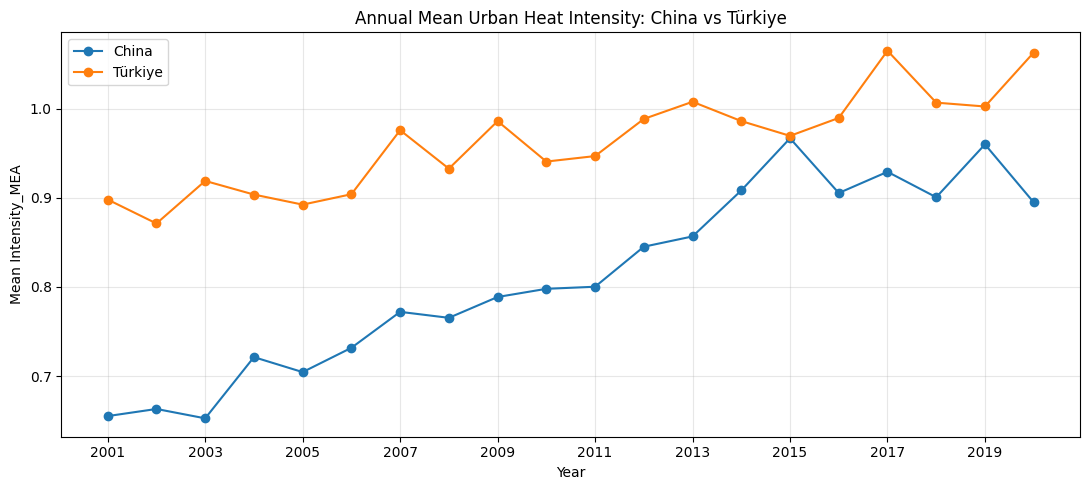

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load the final expanded dataset
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

file_path = os.path.join(
    output_dir,
    "task6_feature_matrix_full_expanded.csv"
)

data = pd.read_csv(file_path)

# Summarize heat intensity for each country
print("Heat intensity summary by country:")

country_summary = (
    data.groupby("Country")["Intensity_MEA"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

display(country_summary)

# Calculate annual mean heat intensity by country
yearly_intensity = (
    data.groupby(["year", "Country"])["Intensity_MEA"]
    .mean()
    .reset_index()
)

print("\nAnnual mean heat intensity:")
display(yearly_intensity.head(10))

# Plot annual mean heat intensity for both countries
plt.figure(figsize=(11, 5))

for country in yearly_intensity["Country"].unique():
    country_data = yearly_intensity[
        yearly_intensity["Country"] == country
    ]

    plt.plot(
        country_data["year"],
        country_data["Intensity_MEA"],
        marker="o",
        label=country
    )

plt.title("Annual Mean Urban Heat Intensity: China vs Türkiye")
plt.xlabel("Year")
plt.ylabel("Mean Intensity_MEA")
plt.xticks(range(2001, 2021, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd

# Load the expanded dataset
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

file_path = os.path.join(
    output_dir,
    "task6_feature_matrix_full_expanded.csv"
)

data = pd.read_csv(file_path)

# Select the variables to investigate
features = [
    "Population_1km_Sum",
    "area_log",
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction",
    "year"
]

# Calculate Spearman correlations separately for each country
# Spearman measures whether two variables tend to increase or decrease together
results = []

for country in ["China", "Türkiye"]:
    country_data = data[data["Country"] == country]

    for feature in features:
        correlation = country_data[
            ["Intensity_MEA", feature]
        ].corr(method="spearman").iloc[0, 1]

        results.append({
            "Country": country,
            "Feature": feature,
            "Spearman_Correlation": correlation
        })

correlation_results = pd.DataFrame(results)

# Display the results, strongest positive associations first
for country in ["China", "Türkiye"]:
    print(f"\n{country}: correlation with Intensity_MEA")

    country_results = (
        correlation_results[
            correlation_results["Country"] == country
        ]
        .sort_values(
            "Spearman_Correlation",
            ascending=False
        )
    )

    display(country_results.round(3))


China: correlation with Intensity_MEA


,Country,Feature,Spearman_Correlation
2,China,UrbanFraction,0.395
0,China,Population_1km_Sum,0.368
1,China,area_log,0.270
8,China,year,0.200
6,China,BarrenSnowFraction,-0.044
7,China,WaterFraction,-0.102
5,China,CropNaturalMosaicFraction,-0.138
4,China,NaturalCoverFraction,-0.193
3,China,CroplandFraction,-0.320



Türkiye: correlation with Intensity_MEA


,Country,Feature,Spearman_Correlation
9,Türkiye,Population_1km_Sum,0.581
11,Türkiye,UrbanFraction,0.408
10,Türkiye,area_log,0.296
17,Türkiye,year,0.073
14,Türkiye,CropNaturalMosaicFraction,-0.067
15,Türkiye,BarrenSnowFraction,-0.109
12,Türkiye,CroplandFraction,-0.127
16,Türkiye,WaterFraction,-0.137
13,Türkiye,NaturalCoverFraction,-0.374


In [ ]:
import os
import pandas as pd

# Load the expanded dataset
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

file_path = os.path.join(
    output_dir,
    "task6_feature_matrix_full_expanded.csv"
)

data = pd.read_csv(file_path)

# Select variables for the city-level comparison
features = [
    "Intensity_MEA",
    "Population_1km_Sum",
    "area_log",
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction"
]

# Calculate each city's average across the 20-year period
city_means = (
    data.groupby(["Country", "UrbanId"])[features]
    .mean()
    .reset_index()
)

print("Number of cities in this comparison:")
print(city_means.groupby("Country")["UrbanId"].nunique())

# Calculate Spearman correlations between city averages
for country in ["China", "Türkiye"]:
    country_means = city_means[
        city_means["Country"] == country
    ]

    results = []

    for feature in features:
        if feature == "Intensity_MEA":
            continue

        correlation = country_means[
            ["Intensity_MEA", feature]
        ].corr(method="spearman").iloc[0, 1]

        results.append({
            "Feature": feature,
            "Spearman_Correlation": correlation
        })

    results = pd.DataFrame(results)

    results["Absolute_Correlation"] = (
        results["Spearman_Correlation"].abs()
    )

    results = results.sort_values(
        "Absolute_Correlation",
        ascending=False
    ).drop(columns="Absolute_Correlation")

    print(f"\n{country}: city-level average correlations")
    display(results.round(3))

Number of cities in this comparison:
Country
China      1441
Türkiye     180
Name: UrbanId, dtype: int64

China: city-level average correlations


,Feature,Spearman_Correlation
2,UrbanFraction,0.445
0,Population_1km_Sum,0.412
3,CroplandFraction,-0.365
1,area_log,0.310
4,NaturalCoverFraction,-0.290
5,CropNaturalMosaicFraction,-0.237
7,WaterFraction,-0.125
6,BarrenSnowFraction,-0.053



Türkiye: city-level average correlations


,Feature,Spearman_Correlation
0,Population_1km_Sum,0.593
2,UrbanFraction,0.419
4,NaturalCoverFraction,-0.412
1,area_log,0.306
3,CroplandFraction,-0.217
7,WaterFraction,-0.148
6,BarrenSnowFraction,-0.109
5,CropNaturalMosaicFraction,-0.096


In [ ]:
import os
import pandas as pd

# Load the expanded dataset
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

file_path = os.path.join(
    output_dir,
    "task6_feature_matrix_full_expanded.csv"
)

data = pd.read_csv(file_path)

# Define variables that can change from year to year
change_features = [
    "Intensity_MEA",
    "Population_1km_Sum",
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction"
]

# Sort observations chronologically within each city
data = data.sort_values(
    ["Country", "UrbanId", "year"]
).copy()

# Calculate year-to-year changes for each city
# This removes each city's fixed starting level from the comparison
for feature in change_features:
    data[f"Change_{feature}"] = (
        data.groupby(["Country", "UrbanId"])[feature]
        .diff()
    )

# Keep rows for which a previous year is available
changes = data.dropna(
    subset=[f"Change_{feature}" for feature in change_features]
).copy()

print("Year-to-year change records:", len(changes))
print("\nRecords by country:")
print(changes.groupby("Country").size())

# Compare changes in heat intensity with changes in other features
features_to_test = [
    "Population_1km_Sum",
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction"
]

for country in ["China", "Türkiye"]:
    country_data = changes[
        changes["Country"] == country
    ]

    results = []

    for feature in features_to_test:
        x = country_data[f"Change_{feature}"]
        y = country_data["Change_Intensity_MEA"]

        # Spearman correlation between year-to-year changes
        correlation = x.corr(y, method="spearman")

        results.append({
            "Feature": feature,
            "Spearman_Correlation_of_Changes": correlation
        })

    results = pd.DataFrame(results)
    results["Absolute_Correlation"] = (
        results["Spearman_Correlation_of_Changes"].abs()
    )

    results = results.sort_values(
        "Absolute_Correlation",
        ascending=False
    ).drop(columns="Absolute_Correlation")

    print(f"\n{country}: year-to-year change correlations")
    display(results.round(3))

Year-to-year change records: 30799

Records by country:
Country
China      27379
Türkiye     3420
dtype: int64

China: year-to-year change correlations


,Feature,Spearman_Correlation_of_Changes
1,UrbanFraction,0.010
0,Population_1km_Sum,-0.009
2,CroplandFraction,-0.005
5,BarrenSnowFraction,-0.004
4,CropNaturalMosaicFraction,0.004
6,WaterFraction,-0.003
3,NaturalCoverFraction,-0.000



Türkiye: year-to-year change correlations


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,Feature,Spearman_Correlation_of_Changes
1,UrbanFraction,0.037
4,CropNaturalMosaicFraction,0.021
5,BarrenSnowFraction,-0.019
3,NaturalCoverFraction,-0.008
2,CroplandFraction,-0.007
0,Population_1km_Sum,0.003
6,WaterFraction,NaN


In [ ]:
# Check whether yearly changes in water fraction are constant

for country in ["China", "Türkiye"]:
    values = changes.loc[
        changes["Country"] == country,
        "Change_WaterFraction"
    ]

    print(f"\n{country}")
    print("Number of unique change values:", values.nunique())
    print("Minimum change:", values.min())
    print("Maximum change:", values.max())
    print("Standard deviation:", values.std())


China
Number of unique change values: 14
Minimum change: -0.1054798859676909
Maximum change: 0.1282863477985429
Standard deviation: 0.0016932420406691796

Türkiye
Number of unique change values: 1
Minimum change: 0.0
Maximum change: 0.0
Standard deviation: 0.0


In [ ]:
import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# Load the expanded dataset
output_dir = (
    "/content/drive/MyDrive/"
    "Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

file_path = os.path.join(
    output_dir,
    "task6_feature_matrix_full_expanded.csv"
)

data = pd.read_csv(file_path)

# Sort observations chronologically within each city
data = data.sort_values(
    ["Country", "UrbanId", "year"]
).copy()

# Log-transform local population to reduce skewness
data["LogPopulation"] = np.log1p(
    data["Population_1km_Sum"]
)

# Define variables for the within-city analysis
variables = [
    "Intensity_MEA",
    "LogPopulation",
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction"
]

# Calculate year-to-year changes within each city
for variable in variables:
    data[f"Change_{variable}"] = (
        data.groupby(["Country", "UrbanId"])[variable]
        .diff()
    )

# Keep observations with a previous year
change_data = data.dropna(
    subset=[f"Change_{variable}" for variable in variables]
).copy()

print("Observations used:", len(change_data))
print("\nObservations by country:")
print(change_data.groupby("Country").size())

# Estimate the model:
# Year effects control for changes common to all cities.
# Country interactions allow associations to differ between countries.
# Standard errors are clustered by city.
formula = (
    "Change_Intensity_MEA ~ C(year) + "
    "C(Country) * ("
    "Change_LogPopulation + "
    "Change_UrbanFraction + "
    "Change_CroplandFraction + "
    "Change_NaturalCoverFraction"
    ")"
)

model = smf.ols(
    formula=formula,
    data=change_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": change_data["UrbanId"]
    }
)

# Display coefficients for the changing features
coefficient_table = pd.DataFrame({
    "Coefficient": model.params,
    "Clustered_Std_Error": model.bse,
    "P_Value": model.pvalues
})

feature_results = coefficient_table[
    coefficient_table.index.str.contains("Change_")
]

print("\nRegression results for changing features:")
display(feature_results.round(4))

print("\nModel R-squared:", round(model.rsquared, 4))
print("Number of city clusters:", change_data["UrbanId"].nunique())

Observations used: 30799

Observations by country:
Country
China      27379
Türkiye     3420
dtype: int64

Regression results for changing features:


,Coefficient,Clustered_Std_Error,P_Value
Change_LogPopulation,-0.0316,0.0174,0.0690
C(Country)[T.Türkiye]:Change_LogPopulation,0.0767,0.0309,0.0131
Change_UrbanFraction,0.0940,0.1632,0.5646
C(Country)[T.Türkiye]:Change_UrbanFraction,0.5334,0.3959,0.1779
Change_CroplandFraction,-0.0073,0.0906,0.9358
C(Country)[T.Türkiye]:Change_CroplandFraction,-0.0270,0.3019,0.9288
Change_NaturalCoverFraction,0.1351,0.0929,0.1461
C(Country)[T.Türkiye]:Change_NaturalCoverFraction,-0.2498,0.2798,0.3721



Model R-squared: 0.0138
Number of city clusters: 1621


In [ ]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs/"
    "task6_feature_matrix_full_expanded.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
for col in df.columns:
    print(col)

Dataset shape: (32420, 19)

Columns:
UrbanId
year
Intensity_MEA
Country
source_file
Longitude
Latitude
Area
area_log
Population_1km_Sum
Population_1km_ValidPixels
LandCover_IGBP_Mode
LandCover_ValidPixels
UrbanFraction
CroplandFraction
NaturalCoverFraction
CropNaturalMosaicFraction
BarrenSnowFraction
WaterFraction


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer"
)

# Find files that may contain the old feature matrix or model inputs.
keywords = [
    "feature", "matrix", "pool", "ndvi",
    "era5", "dem", "baseline", "task6", "task7"
]

files = sorted(PROJECT_ROOT.rglob("*.csv"))

print("Total CSV files found:", len(files))

for file in files:
    name = file.name.lower()

    if any(word in name for word in keywords):
        try:
            columns = pd.read_csv(file, nrows=0).columns.tolist()

            print(f"\nFILE: {file.relative_to(PROJECT_ROOT)}")
            print("COLUMN COUNT:", len(columns))
            print("COLUMNS:", ", ".join(columns))

        except Exception as error:
            print(f"\nCould not inspect: {file.name}")
            print(error)

Total CSV files found: 245

FILE: archive/historical_artifacts/Urban_Heat_Transfer_History_Archive_Not_For_GitHub/ERA5_NC_LOCAL_FILE_MANIFEST.csv
COLUMN COUNT: 5
COLUMNS: filename, size_bytes, sha256, archive_action, content_group

FILE: archive/historical_artifacts/Urban_Heat_Transfer_History_Archive_Not_For_GitHub/legacy_outputs_and_audits/legacy_external_feature_tables/audit_dem_missing_cities.csv
COLUMN COUNT: 2
COLUMNS: UrbanId, missing_dem_years

FILE: archive/historical_artifacts/Urban_Heat_Transfer_History_Archive_Not_For_GitHub/legacy_outputs_and_audits/legacy_external_feature_tables/audit_era5_missing_cities.csv
COLUMN COUNT: 2
COLUMNS: UrbanId, missing_era5_years

FILE: archive/historical_artifacts/Urban_Heat_Transfer_History_Archive_Not_For_GitHub/legacy_outputs_and_audits/legacy_external_feature_tables/audit_no_ndvi_cities.csv
COLUMN COUNT: 2
COLUMNS: UrbanId, valid_ndvi_count

FILE: archive/historical_artifacts/Urban_Heat_Transfer_History_Archive_Not_For_GitHub/legacy_out

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

old_path = ROOT / "task6_feature_matrix_enhanced.csv"
new_path = ROOT / "task6_feature_matrix_full_expanded.csv"

old_df = pd.read_csv(old_path)
new_df = pd.read_csv(new_path)

keys = ["UrbanId", "year"]

print("OLD matrix shape:", old_df.shape)
print("NEW matrix shape:", new_df.shape)

print("\nDuplicate city-year keys:")
print("OLD:", old_df.duplicated(keys).sum())
print("NEW:", new_df.duplicated(keys).sum())

# Check whether both files contain exactly the same city-year records.
old_keys = set(map(tuple, old_df[keys].to_numpy()))
new_keys = set(map(tuple, new_df[keys].to_numpy()))

print("\nCity-year key comparison:")
print("Only in OLD:", len(old_keys - new_keys))
print("Only in NEW:", len(new_keys - old_keys))
print("Keys shared by both:", len(old_keys & new_keys))

# Check common columns for differences.
check_cols = [
    "Intensity_MEA", "Country", "Longitude",
    "Latitude", "Area", "area_log"
]

check_cols = [
    c for c in check_cols
    if c in old_df.columns and c in new_df.columns
]

check = old_df.merge(
    new_df,
    on=keys,
    how="inner",
    suffixes=("_old", "_new"),
    validate="one_to_one"
)

print("\nShared-column differences:")
for col in check_cols:
    a = check[f"{col}_old"]
    b = check[f"{col}_new"]

    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        same = np.isclose(a, b, equal_nan=True)
    else:
        same = (
            a.fillna("<MISSING>").astype(str).to_numpy()
            == b.fillna("<MISSING>").astype(str).to_numpy()
        )

    print(f"{col}: {int((~same).sum())} differing rows")

OLD matrix shape: (32420, 18)
NEW matrix shape: (32420, 19)

Duplicate city-year keys:
OLD: 0
NEW: 0

City-year key comparison:
Only in OLD: 0
Only in NEW: 0
Keys shared by both: 32420

Shared-column differences:
Intensity_MEA: 0 differing rows
Country: 0 differing rows
Longitude: 0 differing rows
Latitude: 0 differing rows
Area: 0 differing rows
area_log: 0 differing rows


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

old_path = ROOT / "task6_feature_matrix_enhanced.csv"
new_path = ROOT / "task6_feature_matrix_full_expanded.csv"

# Load the existing and newly expanded feature matrices.
old_df = pd.read_csv(old_path)
new_df = pd.read_csv(new_path)

KEYS = ["UrbanId", "year"]

# Stop if either dataset contains duplicate city-year records.
assert not old_df.duplicated(KEYS).any(), "Duplicates found in OLD matrix."
assert not new_df.duplicated(KEYS).any(), "Duplicates found in NEW matrix."

# Verify that both matrices contain exactly the same city-year keys.
old_keys = set(map(tuple, old_df[KEYS].to_numpy()))
new_keys = set(map(tuple, new_df[KEYS].to_numpy()))

assert old_keys == new_keys, "City-year keys do not match."

# Verify all shared non-key columns before merging.
shared_cols = [
    c for c in new_df.columns
    if c in old_df.columns and c not in KEYS
]

check = old_df[KEYS + shared_cols].merge(
    new_df[KEYS + shared_cols],
    on=KEYS,
    how="inner",
    suffixes=("_old", "_new"),
    validate="one_to_one"
)

for col in shared_cols:
    a = check[f"{col}_old"]
    b = check[f"{col}_new"]

    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        equal = np.isclose(a, b, equal_nan=True)
    else:
        equal = (
            a.fillna("<MISSING>").astype(str).to_numpy()
            == b.fillna("<MISSING>").astype(str).to_numpy()
        )

    assert equal.all(), f"Shared column differs: {col}"

# Keep only the new feature columns from the expanded matrix.
new_cols = [c for c in new_df.columns if c not in old_df.columns]

# Merge one-to-one by city and year.
integrated = old_df.merge(
    new_df[KEYS + new_cols],
    on=KEYS,
    how="left",
    validate="one_to_one",
    indicator=True
)

assert integrated["_merge"].eq("both").all(), "Some records did not match."

integrated = integrated.drop(columns="_merge")

assert not integrated.duplicated(KEYS).any()
assert len(integrated) == len(old_df)

# Save to a new file; preserve both original matrices.
output_path = ROOT / "task6_feature_matrix_integrated.csv"
integrated.to_csv(output_path, index=False)

print("Integrated matrix shape:", integrated.shape)
print("Original features:", len(old_df.columns))
print("New features added:", new_cols)
print("Total columns:", len(integrated.columns))
print("Duplicate city-year records:", integrated.duplicated(KEYS).sum())
print("Saved to:", output_path)

Integrated matrix shape: (32420, 28)
Original features: 18
New features added: ['Population_1km_Sum', 'Population_1km_ValidPixels', 'LandCover_IGBP_Mode', 'LandCover_ValidPixels', 'UrbanFraction', 'CroplandFraction', 'NaturalCoverFraction', 'CropNaturalMosaicFraction', 'BarrenSnowFraction', 'WaterFraction']
Total columns: 28
Duplicate city-year records: 0
Saved to: /content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/phase2_outputs/task6_feature_matrix_integrated.csv


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

DATA_PATH = ROOT / "task6_feature_matrix_integrated.csv"
df = pd.read_csv(DATA_PATH)

# 1. Check the overall dataset structure.
print("DATASET SHAPE:", df.shape)
print("DUPLICATE CITY-YEAR RECORDS:",
      df.duplicated(["UrbanId", "year"]).sum())
print("MISSING TARGET VALUES:", df["Intensity_MEA"].isna().sum())

# 2. Check country coverage.
print("\nCITIES BY COUNTRY:")
print(df.groupby("Country")["UrbanId"].nunique())

print("\nROWS BY COUNTRY:")
print(df["Country"].value_counts())

# 3. Check missing values in every column.
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})

print("\nMISSINGNESS REPORT:")
print(missing[missing["missing_count"] > 0].to_string())

# 4. Check the new land-cover fractions.
fraction_cols = [
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction"
]

print("\nLAND-COVER FRACTION SUMMARY:")
print(df[fraction_cols].describe().round(4))

fraction_sum = df[fraction_cols].sum(axis=1)

print("\nLAND-COVER FRACTION SUM:")
print("Minimum:", round(fraction_sum.min(), 4))
print("Maximum:", round(fraction_sum.max(), 4))
print("Rows outside 0-1 sum tolerance:",
      int((~np.isclose(fraction_sum, 1.0, atol=0.03)).sum()))

# 5. Check the existing environmental features.
environment_cols = [
    "elevation_m",
    "era5_t2m_jja",
    "era5_precip_jja_mm",
    "era5_wind_jja",
    "era5_dewpoint_jja",
    "era5_rh_jja",
    "ndvi_jja_mean"
]

available_environment_cols = [
    c for c in environment_cols if c in df.columns
]

print("\nENVIRONMENTAL FEATURE COVERAGE:")
print(
    df.groupby("Country")[available_environment_cols]
      .agg(lambda s: s.notna().sum())
      .to_string()
)

DATASET SHAPE: (32420, 28)
DUPLICATE CITY-YEAR RECORDS: 0
MISSING TARGET VALUES: 0

CITIES BY COUNTRY:
Country
China      1441
Türkiye     180
Name: UrbanId, dtype: int64

ROWS BY COUNTRY:
Country
China      28820
Türkiye     3600
Name: count, dtype: int64

MISSINGNESS REPORT:
                     missing_count  missing_percent  unique_values
ndvi_jja_mean                14183            43.75          14665
n_ndvi_observations           8778            27.08              6

LAND-COVER FRACTION SUMMARY:
       UrbanFraction  CroplandFraction  NaturalCoverFraction  \
count     32420.0000        32420.0000            32420.0000   
mean          0.8737            0.0639                0.0477   
std           0.2346            0.1773                0.1364   
min           0.0000            0.0000                0.0000   
25%           0.8777            0.0000                0.0000   
50%           0.9968            0.0000                0.0000   
75%           1.0000            0.0104     

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

old_df = pd.read_csv(ROOT / "task6_feature_matrix_enhanced.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
results = pd.read_csv(ROOT / "task7_transfer_results_all_variants.csv")

# Show the saved city split sizes for each experiment.
print("SAVED SPLIT SIZES")
print(
    manifest.groupby(["pool", "direction", "role"])["UrbanId"]
    .nunique()
    .to_string()
)

# Compare the old experiment's expected test-row counts
# with the rows available for its locked test cities.
checks = [
    ("PRIMARY_COMMON_POOL", "dem_era5"),
    ("NDVI_COMPLETE_SUBSET", "dem_era5_ndvi"),
]

for pool_name, feature_set in checks:
    direction = "Turkiye_to_China"
    locked = manifest[
        (manifest["pool"] == pool_name)
        & (manifest["direction"] == direction)
        & (manifest["role"] == "TARGET_TEST_LOCKED")
    ]

    test_ids = set(locked["UrbanId"].astype(int))
    test_rows = old_df[old_df["UrbanId"].astype(int).isin(test_ids)]

    expected = results[
        (results["pool"] == pool_name)
        & (results["feature_set"] == feature_set)
        & (results["direction"] == direction)
        & (results["model"] == "rf")
        & (results["few_shot_ratio"] == 0.50)
    ]

    print(f"\n--- {pool_name} ---")
    print("Locked test cities:", len(test_ids))
    print("All old-matrix rows for these cities:", len(test_rows))
    print("Rows with valid NDVI:", test_rows["ndvi_jja_mean"].notna().sum())
    print("Recorded test-row counts:", sorted(expected["n_test_rows"].unique()))
    print("Recorded test-city counts:", sorted(expected["n_test_cities"].unique()))
    print("Recorded R² values:", expected["r2"].round(6).tolist())

SAVED SPLIT SIZES
pool                  direction         role                  
NDVI_COMPLETE_SUBSET  China_to_Turkiye  SOURCE_TRAIN              1313
                                        TARGET_ADAPTATION_POOL     142
                                        TARGET_TEST_LOCKED          35
                      Turkiye_to_China  SOURCE_TRAIN               177
                                        TARGET_ADAPTATION_POOL    1050
                                        TARGET_TEST_LOCKED         263
PRIMARY_COMMON_POOL   China_to_Turkiye  SOURCE_TRAIN              1441
                                        TARGET_ADAPTATION_POOL     144
                                        TARGET_TEST_LOCKED          36
                      Turkiye_to_China  SOURCE_TRAIN               180
                                        TARGET_ADAPTATION_POOL    1153
                                        TARGET_TEST_LOCKED         288

--- PRIMARY_COMMON_POOL ---
Locked test cities: 288
All old-matrix

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

integrated = pd.read_csv(
    ROOT / "task6_feature_matrix_integrated.csv"
)

old_matrix = pd.read_csv(
    ROOT / "task6_feature_matrix_enhanced.csv"
)

manifest = pd.read_csv(
    ROOT / "task7_split_manifest_enhanced.csv"
)

old_results = pd.read_csv(
    ROOT / "task7_transfer_results_all_variants.csv"
)

# Verify the integrated matrix still matches the old matrix
# on all original columns.
keys = ["UrbanId", "year"]
shared = [
    c for c in old_matrix.columns
    if c in integrated.columns and c not in keys
]

check = old_matrix[keys + shared].merge(
    integrated[keys + shared],
    on=keys,
    how="outer",
    suffixes=("_old", "_new"),
    validate="one_to_one",
    indicator=True
)

print("Integrated matrix:", integrated.shape)
print("Old matrix:", old_matrix.shape)
print("Unmatched city-year records:",
      int((check["_merge"] != "both").sum()))

for col in shared:
    a = check[f"{col}_old"]
    b = check[f"{col}_new"]

    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        equal = (a.eq(b)) | (a.isna() & b.isna())
    else:
        equal = (
            a.fillna("<MISSING>").astype(str)
            == b.fillna("<MISSING>").astype(str)
        )

    print(f"{col}: differing values = {int((~equal).sum())}")

# Reconstruct the two old data pools.
pools = {
    "PRIMARY_COMMON_POOL": integrated.copy(),
    "NDVI_COMPLETE_SUBSET": integrated[
        integrated["ndvi_jja_mean"].notna()
    ].copy()
}

# Compare the locked test rows against the original experiment.
for pool_name, data in pools.items():
    variant = (
        "dem_era5"
        if pool_name == "PRIMARY_COMMON_POOL"
        else "dem_era5_ndvi"
    )

    print(f"\n--- {pool_name} ---")
    print("Rows:", len(data))
    print("Cities:", data["UrbanId"].nunique())

    for direction in ["China_to_Turkiye", "Turkiye_to_China"]:
        split = manifest[
            (manifest["pool"] == pool_name)
            & (manifest["direction"] == direction)
            & (manifest["role"] == "TARGET_TEST_LOCKED")
        ]

        test_ids = set(split["UrbanId"].astype(int))
        actual = data[data["UrbanId"].astype(int).isin(test_ids)]

        recorded = old_results[
            (old_results["pool"] == pool_name)
            & (old_results["direction"] == direction)
            & (old_results["feature_set"] == variant)
            & (old_results["model"] == "rf")
            & (old_results["few_shot_ratio"] == 0.50)
        ]

        print(
            direction,
            "| actual rows:", len(actual),
            "| expected rows:", sorted(recorded["n_test_rows"].unique()),
            "| actual cities:", actual["UrbanId"].nunique(),
            "| expected cities:", sorted(recorded["n_test_cities"].unique())
        )

Integrated matrix: (32420, 28)
Old matrix: (32420, 18)
Unmatched city-year records: 0
Intensity_MEA: differing values = 1
Country: differing values = 0
source_file: differing values = 0
Longitude: differing values = 0
Latitude: differing values = 0
Area: differing values = 0
area_log: differing values = 0
elevation_m: differing values = 0
era5_t2m_jja: differing values = 0
era5_precip_jja_mm: differing values = 0
era5_wind_jja: differing values = 0
era5_dewpoint_jja: differing values = 0
era5_rh_jja: differing values = 0
era5_months_available: differing values = 0
ndvi_jja_mean: differing values = 0
n_ndvi_observations: differing values = 0

--- PRIMARY_COMMON_POOL ---
Rows: 32420
Cities: 1621
China_to_Turkiye | actual rows: 720 | expected rows: [np.int64(720)] | actual cities: 36 | expected cities: [np.int64(36)]
Turkiye_to_China | actual rows: 5760 | expected rows: [np.int64(5760)] | actual cities: 288 | expected cities: [np.int64(288)]

--- NDVI_COMPLETE_SUBSET ---
Rows: 18237
Citie

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

old_matrix = pd.read_csv(
    ROOT / "task6_feature_matrix_enhanced.csv"
)

integrated = pd.read_csv(
    ROOT / "task6_feature_matrix_integrated.csv"
)

keys = ["UrbanId", "year"]

comparison = old_matrix[
    keys + ["Intensity_MEA", "source_file"]
].merge(
    integrated[keys + ["Intensity_MEA", "source_file"]],
    on=keys,
    how="inner",
    suffixes=("_current", "_integrated"),
    validate="one_to_one"
)

a = comparison["Intensity_MEA_current"].to_numpy()
b = comparison["Intensity_MEA_integrated"].to_numpy()

same = np.isclose(a, b, rtol=1e-12, atol=1e-12, equal_nan=True)
differences = comparison.loc[~same].copy()

print("Meaningful target differences:", len(differences))

if len(differences):
    print(
        differences[
            [
                "UrbanId",
                "year",
                "Intensity_MEA_current",
                "Intensity_MEA_integrated",
                "source_file_current",
                "source_file_integrated",
            ]
        ].to_string(index=False)
    )

    # Check whether the differing city belongs to any locked test set.
    manifest = pd.read_csv(
        ROOT / "task7_split_manifest_enhanced.csv"
    )

    for _, row in differences.iterrows():
        city_id = int(row["UrbanId"])

        print(f"\nCity {city_id}, year {int(row['year'])}:")
        for (pool, direction), group in manifest.groupby(
            ["pool", "direction"]
        ):
            locked_ids = set(
                group.loc[
                    group["role"].eq("TARGET_TEST_LOCKED"),
                    "UrbanId"
                ].astype(int)
            )
            print(
                f"{pool} | {direction}: "
                f"{'LOCKED TEST CITY' if city_id in locked_ids else 'not a test city'}"
            )
else:
    print("The previous difference was only a floating-point precision issue.")

Meaningful target differences: 0
The previous difference was only a floating-point precision issue.


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

# --------------------------------------------------
# 1. Load the integrated data and original experiment
# --------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

df = pd.read_csv(ROOT / "task6_feature_matrix_integrated.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(
    ROOT / "task7_few_shot_selections_enhanced.csv"
)
old_results = pd.read_csv(
    ROOT / "task7_transfer_results_all_variants.csv"
)

TARGET = "Intensity_MEA"
KEYS = ["UrbanId", "year"]

assert not df.duplicated(KEYS).any()
assert df[TARGET].notna().all()

# Population is highly skewed, so use log(1 + population).
assert (df["Population_1km_Sum"] >= 0).all()
df["log_population_1km"] = np.log1p(df["Population_1km_Sum"])

# --------------------------------------------------
# 2. Define appropriate predictors
# --------------------------------------------------

BASELINE_FEATURES = [
    "year", "Longitude", "Latitude", "area_log"
]

DEM_ERA5_FEATURES = [
    "elevation_m",
    "era5_t2m_jja",
    "era5_precip_jja_mm",
    "era5_wind_jja",
    "era5_dewpoint_jja",
    "era5_rh_jja",
]

NEW_NUMERIC_FEATURES = [
    "log_population_1km",
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction",
]

CATEGORICAL_FEATURES = ["LandCover_IGBP_Mode"]

NUMERIC_FEATURES = (
    BASELINE_FEATURES
    + DEM_ERA5_FEATURES
    + NEW_NUMERIC_FEATURES
)

# The main pool has no NDVI predictor, allowing all rows to be used.
FEATURE_SETS = {
    "PRIMARY_COMMON_POOL": NUMERIC_FEATURES,
    "NDVI_COMPLETE_SUBSET": NUMERIC_FEATURES + ["ndvi_jja_mean"],
}

for pool_name, features in FEATURE_SETS.items():
    needed = features + CATEGORICAL_FEATURES + [TARGET, "UrbanId"]
    missing = set(needed) - set(df.columns)
    assert not missing, f"{pool_name} is missing: {missing}"

# Keep the exact original data-pool definitions.
pools = {
    "PRIMARY_COMMON_POOL": df.copy(),
    "NDVI_COMPLETE_SUBSET": df[df["ndvi_jja_mean"].notna()].copy(),
}

print("DATA POOLS")
for name, pool_df in pools.items():
    print(
        name,
        "| rows:", len(pool_df),
        "| cities:", pool_df["UrbanId"].nunique()
    )

# --------------------------------------------------
# 3. Build models with appropriate preprocessing
# --------------------------------------------------

def make_model(model_name, numeric_features, seed):
    if model_name == "source_mean":
        # The mean baseline does not need feature preprocessing.
        return None

    if model_name == "ridge":
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
    elif model_name == "rf":
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ])
    else:
        raise ValueError(f"Unknown model: {model_name}")

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        (
            "categorical",
            categorical_pipeline,
            CATEGORICAL_FEATURES,
        ),
    ])

    if model_name == "ridge":
        estimator = Ridge(alpha=1.0)
    else:
        estimator = RandomForestRegressor(
            n_estimators=100,
            max_depth=10,
            random_state=seed,
            n_jobs=-1,
        )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", estimator),
    ])


def score_predictions(test_df, y_true, y_pred):
    residual = np.asarray(y_true) - np.asarray(y_pred)

    city_errors = pd.DataFrame({
        "UrbanId": test_df["UrbanId"].to_numpy(),
        "absolute_error": np.abs(residual),
        "squared_error": residual ** 2,
    }).groupby("UrbanId").agg(
        city_mae=("absolute_error", "mean"),
        city_mse=("squared_error", "mean"),
    )

    return {
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "macro_city_mae": float(city_errors["city_mae"].mean()),
        "macro_city_rmse": float(np.sqrt(city_errors["city_mse"].mean())),
    }


# --------------------------------------------------
# 4. Reuse the locked cities and saved few-shot choices
# --------------------------------------------------

few_shot_ratios = [0.0, 0.01, 0.05, 0.10, 0.20, 0.50]
adaptation_seeds = list(range(10))
models = ["source_mean", "ridge", "rf"]

results = []
jobs_total = (
    len(pools) * 2
    * (1 + (len(few_shot_ratios) - 1) * len(adaptation_seeds))
    * len(models)
)
jobs_done = 0

for pool_name, pool_df in pools.items():
    numeric_features = FEATURE_SETS[pool_name]
    all_features = numeric_features + CATEGORICAL_FEATURES

    for direction in ["China_to_Turkiye", "Turkiye_to_China"]:
        split = manifest[
            (manifest["pool"] == pool_name)
            & (manifest["direction"] == direction)
        ]

        source_ids = set(
            split.loc[
                split["role"] == "SOURCE_TRAIN", "UrbanId"
            ].astype(int)
        )
        adaptation_ids = set(
            split.loc[
                split["role"] == "TARGET_ADAPTATION_POOL", "UrbanId"
            ].astype(int)
        )
        test_ids = set(
            split.loc[
                split["role"] == "TARGET_TEST_LOCKED", "UrbanId"
            ].astype(int)
        )

        assert source_ids.isdisjoint(adaptation_ids)
        assert source_ids.isdisjoint(test_ids)
        assert adaptation_ids.isdisjoint(test_ids)

        test_df = pool_df[
            pool_df["UrbanId"].astype(int).isin(test_ids)
        ].copy()

        assert set(test_df["UrbanId"].astype(int).unique()) == test_ids

        for ratio in few_shot_ratios:
            seeds = [0] if ratio == 0 else adaptation_seeds

            for seed in seeds:
                saved_shots = selections[
                    (selections["pool"] == pool_name)
                    & (selections["direction"] == direction)
                    & (
                        np.isclose(
                            selections["ratio_of_adaptation_pool"],
                            ratio,
                        )
                    )
                    & (selections["seed"] == seed)
                ]

                shot_ids = set(saved_shots["UrbanId"].astype(int))

                assert shot_ids.issubset(adaptation_ids)
                assert shot_ids.isdisjoint(test_ids)

                train_ids = source_ids | shot_ids
                assert train_ids.isdisjoint(test_ids)

                train_df = pool_df[
                    pool_df["UrbanId"].astype(int).isin(train_ids)
                ].copy()

                assert not train_df.empty
                assert not test_df.empty

                X_train = train_df[all_features]
                X_test = test_df[all_features]
                y_train = train_df[TARGET]
                y_test = test_df[TARGET].to_numpy()

                for model_name in models:
                    estimator = make_model(
                        model_name,
                        numeric_features,
                        seed,
                    )

                    if model_name == "source_mean":
                        # Equivalent to a mean-prediction DummyRegressor.
                        predictions = np.full(
                            len(test_df), y_train.mean()
                        )
                    else:
                        estimator.fit(X_train, y_train)
                        predictions = estimator.predict(X_test)

                    overlap = len(
                        set(train_df["UrbanId"].astype(int))
                        & set(test_df["UrbanId"].astype(int))
                    )
                    assert overlap == 0

                    results.append({
                        "pool": pool_name,
                        "direction": direction,
                        "feature_set": "integrated_all_features",
                        "model": model_name,
                        "few_shot_ratio": ratio,
                        "seed": seed,
                        "n_source_cities": len(source_ids),
                        "n_adaptation_pool_cities": len(adaptation_ids),
                        "n_shot_cities": len(shot_ids),
                        "n_test_cities": len(test_ids),
                        "n_train_rows": len(train_df),
                        "n_test_rows": len(test_df),
                        "test_city_overlap": overlap,
                        **score_predictions(test_df, y_test, predictions),
                    })

                    jobs_done += 1

                    # Save checkpoints in a NEW file, not over the old results.
                    if jobs_done % 30 == 0:
                        pd.DataFrame(results).to_csv(
                            ROOT / "task7_integrated_transfer_results.csv",
                            index=False,
                        )
                        print(f"Completed {jobs_done}/{jobs_total} model runs")

# Final output for the new integrated experiment.
integrated_results = pd.DataFrame(results)

assert len(integrated_results) == jobs_total
assert integrated_results["test_city_overlap"].eq(0).all()

integrated_results.to_csv(
    ROOT / "task7_integrated_transfer_results.csv",
    index=False,
)

# --------------------------------------------------
# 5. Compare against the original results, paired by
#    pool, direction, model, few-shot ratio and seed.
# --------------------------------------------------

reference_feature_sets = {
    "PRIMARY_COMMON_POOL": "dem_era5",
    "NDVI_COMPLETE_SUBSET": "dem_era5_ndvi",
}

old_parts = []

for pool_name, old_feature_set in reference_feature_sets.items():
    part = old_results[
        (old_results["pool"] == pool_name)
        & (old_results["feature_set"] == old_feature_set)
    ].copy()

    old_parts.append(part)

old_reference = pd.concat(old_parts, ignore_index=True)

metrics = [
    "r2", "rmse", "mae",
    "macro_city_mae", "macro_city_rmse",
]

# Round the ratio for robust matching of floating-point values.
integrated_results["ratio_key"] = (
    integrated_results["few_shot_ratio"].round(5)
)
old_reference["ratio_key"] = (
    old_reference["few_shot_ratio"].round(5)
)

join_keys = [
    "pool", "direction", "model", "seed", "ratio_key"
]

old_reference = old_reference[
    join_keys + metrics
].rename(
    columns={metric: f"{metric}_old" for metric in metrics}
)

comparison = integrated_results.merge(
    old_reference,
    on=join_keys,
    how="inner",
    validate="one_to_one",
)

assert len(comparison) == len(integrated_results), (
    "Some integrated runs did not match an old result."
)

for metric in metrics:
    comparison[f"delta_{metric}"] = (
        comparison[metric] - comparison[f"{metric}_old"]
    )

comparison.to_csv(
    ROOT / "task7_integrated_vs_old_comparison.csv",
    index=False,
)

# Average across seeds for each few-shot setting.
summary = comparison.groupby(
    ["pool", "direction", "model", "few_shot_ratio"],
    as_index=False,
).agg(
    old_r2_mean=("r2_old", "mean"),
    integrated_r2_mean=("r2", "mean"),
    delta_r2_mean=("delta_r2", "mean"),
    old_rmse_mean=("rmse_old", "mean"),
    integrated_rmse_mean=("rmse", "mean"),
    delta_rmse_mean=("delta_rmse", "mean"),
    old_mae_mean=("mae_old", "mean"),
    integrated_mae_mean=("mae", "mean"),
    delta_mae_mean=("delta_mae", "mean"),
)

summary.to_csv(
    ROOT / "task7_integrated_vs_old_summary.csv",
    index=False,
)

print("\nEXPERIMENT COMPLETE")
print("Integrated model runs:", len(integrated_results))
print("Paired comparisons:", len(comparison))
print("Saved new results and comparison files.")

# Highlight the comparison relevant to the previous ~0.269 result.
focus = comparison[
    (comparison["direction"] == "Turkiye_to_China")
    & (comparison["model"] == "rf")
    & np.isclose(comparison["few_shot_ratio"], 0.50)
]

print("\nKEY COMPARISON: Türkiye -> China | Random Forest | 50% few-shot")
print(
    focus.groupby("pool").agg(
        old_r2=("r2_old", "mean"),
        integrated_r2=("r2", "mean"),
        delta_r2=("delta_r2", "mean"),
        old_rmse=("rmse_old", "mean"),
        integrated_rmse=("rmse", "mean"),
        delta_rmse=("delta_rmse", "mean"),
        old_mae=("mae_old", "mean"),
        integrated_mae=("mae", "mean"),
        delta_mae=("delta_mae", "mean"),
    ).round(6).to_string()
)

DATA POOLS
PRIMARY_COMMON_POOL | rows: 32420 | cities: 1621
NDVI_COMPLETE_SUBSET | rows: 18237 | cities: 1490
Completed 30/612 model runs
Completed 60/612 model runs
Completed 90/612 model runs
Completed 120/612 model runs
Completed 150/612 model runs
Completed 180/612 model runs
Completed 210/612 model runs
Completed 240/612 model runs
Completed 270/612 model runs
Completed 300/612 model runs
Completed 330/612 model runs
Completed 360/612 model runs
Completed 390/612 model runs
Completed 420/612 model runs
Completed 450/612 model runs
Completed 480/612 model runs
Completed 510/612 model runs
Completed 540/612 model runs
Completed 570/612 model runs
Completed 600/612 model runs

EXPERIMENT COMPLETE
Integrated model runs: 612
Paired comparisons: 612
Saved new results and comparison files.

KEY COMPARISON: Türkiye -> China | Random Forest | 50% few-shot
                        old_r2  integrated_r2  delta_r2  old_rmse  integrated_rmse  delta_rmse   old_mae  integrated_mae  delta_mae
pool

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

comparison = pd.read_csv(
    ROOT / "task7_integrated_vs_old_comparison.csv"
)

# Focus on Random Forest and compare every few-shot setting.
rf = comparison[comparison["model"] == "rf"].copy()

report = (
    rf.groupby(["pool", "direction", "few_shot_ratio"])
    .agg(
        old_r2=("r2_old", "mean"),
        new_r2=("r2", "mean"),
        delta_r2=("delta_r2", "mean"),
        old_rmse=("rmse_old", "mean"),
        new_rmse=("rmse", "mean"),
        delta_rmse=("delta_rmse", "mean"),
        old_mae=("mae_old", "mean"),
        new_mae=("mae", "mean"),
        delta_mae=("delta_mae", "mean"),
        delta_r2_sd=("delta_r2", "std"),
    )
    .reset_index()
    .sort_values(["pool", "direction", "few_shot_ratio"])
)

print(report.round(4).to_string(index=False))

report.to_csv(
    ROOT / "task7_integrated_random_forest_summary.csv",
    index=False
)
print("\nSaved summary: task7_integrated_random_forest_summary.csv")

                pool        direction  few_shot_ratio  old_r2  new_r2  delta_r2  old_rmse  new_rmse  delta_rmse  old_mae  new_mae  delta_mae  delta_r2_sd
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.00  0.2804  0.4925    0.2121    0.6142    0.5158     -0.0984   0.5057   0.3941    -0.1116          NaN
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.01  0.2735  0.5075    0.2340    0.6163    0.5079     -0.1084   0.5059   0.3890    -0.1169       0.0796
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.05  0.2714  0.4758    0.2045    0.6161    0.5233     -0.0928   0.4861   0.3976    -0.0886       0.1144
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.10  0.3348  0.4787    0.1439    0.5898    0.5221     -0.0677   0.4616   0.3894    -0.0722       0.1033
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.20  0.2362  0.4011    0.1649    0.6309    0.5585     -0.0724   0.4856   0.4042    -0.0814       0.0578
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.50  0.2011  0.4062    0.2

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

comparison = pd.read_csv(
    ROOT / "task7_integrated_vs_old_comparison.csv"
)

# Focus on Random Forest results.
rf = comparison[comparison["model"] == "rf"].copy()

summary = (
    rf.groupby(["pool", "direction", "few_shot_ratio"])
    .agg(
        n_runs=("delta_r2", "count"),
        mean_delta_r2=("delta_r2", "mean"),
        sd_delta_r2=("delta_r2", "std"),
        r2_improved_runs=("delta_r2", lambda x: (x > 0).sum()),
        rmse_improved_runs=("delta_rmse", lambda x: (x < 0).sum()),
        mae_improved_runs=("delta_mae", lambda x: (x < 0).sum()),
    )
    .reset_index()
)

for metric in [
    "r2_improved_runs",
    "rmse_improved_runs",
    "mae_improved_runs",
]:
    summary[metric.replace("_runs", "_pct")] = (
        summary[metric] / summary["n_runs"] * 100
    ).round(1)

print(summary.round(4).to_string(index=False))

summary.to_csv(
    ROOT / "task7_integrated_rf_stability.csv",
    index=False
)

print("\nSaved: task7_integrated_rf_stability.csv")

                pool        direction  few_shot_ratio  n_runs  mean_delta_r2  sd_delta_r2  r2_improved_runs  rmse_improved_runs  mae_improved_runs  r2_improved_pct  rmse_improved_pct  mae_improved_pct
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.00       1         0.2121          NaN                 1                   1                  1            100.0              100.0             100.0
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.01      10         0.2340       0.0796                10                  10                 10            100.0              100.0             100.0
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.05      10         0.2045       0.1144                10                  10                 10            100.0              100.0             100.0
NDVI_COMPLETE_SUBSET China_to_Turkiye            0.10      10         0.1439       0.1033                10                  10                 10            100.0              100.0             1

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

# Load the integrated matrix and the saved original experiment splits.
df = pd.read_csv(ROOT / "task6_feature_matrix_integrated.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(
    ROOT / "task7_few_shot_selections_enhanced.csv"
)

TARGET = "Intensity_MEA"
KEYS = ["UrbanId", "year"]

assert not df.duplicated(KEYS).any()
assert df[TARGET].notna().all()

# Log transform reduces the skew of the local population proxy.
assert (df["Population_1km_Sum"] >= 0).all()
df["log_population_1km"] = np.log1p(df["Population_1km_Sum"])

BASELINE_FEATURES = [
    "year", "Longitude", "Latitude", "area_log"
]

DEM_ERA5_FEATURES = [
    "elevation_m",
    "era5_t2m_jja",
    "era5_precip_jja_mm",
    "era5_wind_jja",
    "era5_dewpoint_jja",
    "era5_rh_jja",
]

POPULATION_FEATURES = ["log_population_1km"]

LANDCOVER_FRACTIONS = [
    "UrbanFraction",
    "CroplandFraction",
    "NaturalCoverFraction",
    "CropNaturalMosaicFraction",
    "BarrenSnowFraction",
    "WaterFraction",
]

LANDCOVER_CATEGORY = ["LandCover_IGBP_Mode"]

# No NDVI filtering in the primary pool.
pools = {
    "PRIMARY_COMMON_POOL": df.copy(),
    "NDVI_COMPLETE_SUBSET": df[df["ndvi_jja_mean"].notna()].copy(),
}

def build_variants(pool_name):
    legacy = BASELINE_FEATURES + DEM_ERA5_FEATURES

    if pool_name == "NDVI_COMPLETE_SUBSET":
        legacy = legacy + ["ndvi_jja_mean"]

    return {
        "A_legacy": {
            "numeric": legacy,
            "categorical": [],
        },
        "B_plus_population": {
            "numeric": legacy + POPULATION_FEATURES,
            "categorical": [],
        },
        "C_plus_landcover_fractions": {
            "numeric": legacy + LANDCOVER_FRACTIONS,
            "categorical": [],
        },
        "D_population_and_fractions": {
            "numeric": legacy + POPULATION_FEATURES + LANDCOVER_FRACTIONS,
            "categorical": [],
        },
        "E_full_with_landcover_category": {
            "numeric": legacy + POPULATION_FEATURES + LANDCOVER_FRACTIONS,
            "categorical": LANDCOVER_CATEGORY,
        },
    }

def make_rf(numeric_features, categorical_features, seed):
    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=seed,
        n_jobs=-1,
    )

    # Keep the legacy numeric-only preprocessing unchanged.
    if not categorical_features:
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", rf),
        ])

    # LandCover_IGBP_Mode is categorical, so encode it explicitly.
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessing = ColumnTransformer([
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features,
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features,
        ),
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", rf),
    ])

def score_predictions(test_df, y_true, y_pred):
    residual = np.asarray(y_true) - np.asarray(y_pred)

    by_city = pd.DataFrame({
        "UrbanId": test_df["UrbanId"].to_numpy(),
        "absolute_error": np.abs(residual),
        "squared_error": residual ** 2,
    }).groupby("UrbanId").agg(
        city_mae=("absolute_error", "mean"),
        city_mse=("squared_error", "mean"),
    )

    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "mae": mean_absolute_error(y_true, y_pred),
        "macro_city_mae": by_city["city_mae"].mean(),
        "macro_city_rmse": np.sqrt(by_city["city_mse"].mean()),
    }

# Use 20% and 50% few-shot, with the same ten saved seeds.
# This focuses the ablation on the main adaptation scenarios.
RATIOS = [0.20, 0.50]
SEEDS = list(range(10))
DIRECTIONS = ["China_to_Turkiye", "Turkiye_to_China"]

results = []
total_runs = (
    len(pools) * len(DIRECTIONS) * len(RATIOS)
    * len(SEEDS) * 5
)
done = 0

for pool_name, pool_df in pools.items():
    variants = build_variants(pool_name)

    for direction in DIRECTIONS:
        split = manifest[
            (manifest["pool"] == pool_name)
            & (manifest["direction"] == direction)
        ]

        source_ids = set(
            split.loc[
                split["role"] == "SOURCE_TRAIN", "UrbanId"
            ].astype(int)
        )
        adaptation_ids = set(
            split.loc[
                split["role"] == "TARGET_ADAPTATION_POOL", "UrbanId"
            ].astype(int)
        )
        test_ids = set(
            split.loc[
                split["role"] == "TARGET_TEST_LOCKED", "UrbanId"
            ].astype(int)
        )

        assert source_ids.isdisjoint(test_ids)
        assert adaptation_ids.isdisjoint(test_ids)

        test_df = pool_df[
            pool_df["UrbanId"].astype(int).isin(test_ids)
        ].copy()

        assert set(test_df["UrbanId"].astype(int).unique()) == test_ids

        for ratio in RATIOS:
            for seed in SEEDS:
                saved_shots = selections[
                    (selections["pool"] == pool_name)
                    & (selections["direction"] == direction)
                    & np.isclose(
                        selections["ratio_of_adaptation_pool"], ratio
                    )
                    & (selections["seed"] == seed)
                ]

                shots = set(saved_shots["UrbanId"].astype(int))

                assert shots.issubset(adaptation_ids)
                assert shots.isdisjoint(test_ids)

                train_ids = source_ids | shots
                assert train_ids.isdisjoint(test_ids)

                train_df = pool_df[
                    pool_df["UrbanId"].astype(int).isin(train_ids)
                ].copy()

                assert not train_df.empty
                assert not test_df.empty

                for variant_name, spec in variants.items():
                    numeric_features = spec["numeric"]
                    categorical_features = spec["categorical"]
                    features = numeric_features + categorical_features

                    model = make_rf(
                        numeric_features,
                        categorical_features,
                        seed,
                    )

                    model.fit(
                        train_df[features],
                        train_df[TARGET],
                    )

                    predictions = model.predict(test_df[features])

                    assert (
                        set(train_df["UrbanId"].astype(int))
                        .isdisjoint(set(test_df["UrbanId"].astype(int)))
                    )

                    results.append({
                        "pool": pool_name,
                        "direction": direction,
                        "ratio": ratio,
                        "seed": seed,
                        "variant": variant_name,
                        "n_test_cities": len(test_ids),
                        "n_test_rows": len(test_df),
                        **score_predictions(
                            test_df,
                            test_df[TARGET].to_numpy(),
                            predictions,
                        ),
                    })

                    done += 1

                    # Save progress to a new file, preserving old results.
                    if done % 40 == 0:
                        pd.DataFrame(results).to_csv(
                            ROOT / "task7_feature_ablation_results.csv",
                            index=False,
                        )
                        print(f"Completed {done}/{total_runs} fits")

ablation = pd.DataFrame(results)
assert len(ablation) == total_runs

ablation.to_csv(
    ROOT / "task7_feature_ablation_results.csv",
    index=False,
)

# Paired comparison: same pool, direction, ratio and seed.
metric_names = [
    "r2", "rmse", "mae",
    "macro_city_mae", "macro_city_rmse",
]

pair_keys = ["pool", "direction", "ratio", "seed"]

legacy = ablation[
    ablation["variant"] == "A_legacy"
][pair_keys + metric_names].rename(
    columns={m: f"{m}_legacy" for m in metric_names}
)

paired_parts = []

for variant_name in [
    "B_plus_population",
    "C_plus_landcover_fractions",
    "D_population_and_fractions",
    "E_full_with_landcover_category",
]:
    current = ablation[
    ablation["variant"] == variant_name
][pair_keys + metric_names].rename(
    columns={m: f"{m}_variant" for m in metric_names}
)

    paired = legacy.merge(
        current,
        on=pair_keys,
        how="inner",
        validate="one_to_one",
        suffixes=("_legacy", "_variant"),
    )

    paired["variant"] = variant_name

    for metric in metric_names:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_variant"]
            - paired[f"{metric}_legacy"]
        )

    paired_parts.append(paired)

paired_ablation = pd.concat(paired_parts, ignore_index=True)

paired_ablation.to_csv(
    ROOT / "task7_feature_ablation_paired.csv",
    index=False,
)

# Summarize the mean effect and the percentage of seeds that improved.
summary = paired_ablation.groupby(
    ["pool", "direction", "ratio", "variant"],
    as_index=False,
).agg(
    mean_delta_r2=("delta_r2", "mean"),
    sd_delta_r2=("delta_r2", "std"),
    r2_win_rate=("delta_r2", lambda x: (x > 0).mean() * 100),
    mean_delta_rmse=("delta_rmse", "mean"),
    rmse_win_rate=("delta_rmse", lambda x: (x < 0).mean() * 100),
    mean_delta_mae=("delta_mae", "mean"),
    mae_win_rate=("delta_mae", lambda x: (x < 0).mean() * 100),
)

summary.to_csv(
    ROOT / "task7_feature_ablation_summary.csv",
    index=False,
)

print("\nFEATURE ABLATION COMPLETE")
print("Model fits:", len(ablation))
print(summary.round(4).to_string(index=False))
print("\nSaved feature-ablation results and summaries.")

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

file_path = ROOT / "task7_feature_ablation_results.csv"

ablation = pd.read_csv(file_path)

print("Kaydedilmiş model sonuçları:", len(ablation))
print("Beklenen toplam:", 400)
print("Sütunlar:", ablation.columns.tolist())

Kaydedilmiş model sonuçları: 400
Beklenen toplam: 400
Sütunlar: ['pool', 'direction', 'ratio', 'seed', 'variant', 'n_test_cities', 'n_test_rows', 'r2', 'rmse', 'mae', 'macro_city_mae', 'macro_city_rmse']


In [ ]:
# Compare each feature combination against the baseline model.

metric_names = [
    "r2", "rmse", "mae",
    "macro_city_mae", "macro_city_rmse"
]

pair_keys = ["pool", "direction", "ratio", "seed"]

legacy = ablation[
    ablation["variant"] == "A_legacy"
][pair_keys + metric_names].rename(
    columns={m: f"{m}_legacy" for m in metric_names}
)

paired_parts = []

for variant_name in [
    "B_plus_population",
    "C_plus_landcover_fractions",
    "D_population_and_fractions",
    "E_full_with_landcover_category",
]:
    current = ablation[
        ablation["variant"] == variant_name
    ][pair_keys + metric_names].rename(
        columns={m: f"{m}_variant" for m in metric_names}
    )

    paired = legacy.merge(
        current,
        on=pair_keys,
        how="inner",
        validate="one_to_one"
    )

    paired["variant"] = variant_name

    for metric in metric_names:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_variant"]
            - paired[f"{metric}_legacy"]
        )

    paired_parts.append(paired)

paired_ablation = pd.concat(paired_parts, ignore_index=True)

paired_ablation.to_csv(
    ROOT / "task7_feature_ablation_paired.csv",
    index=False
)

summary = paired_ablation.groupby(
    ["pool", "direction", "ratio", "variant"],
    as_index=False
).agg(
    mean_delta_r2=("delta_r2", "mean"),
    sd_delta_r2=("delta_r2", "std"),
    r2_win_rate=("delta_r2", lambda x: (x > 0).mean() * 100),
    mean_delta_rmse=("delta_rmse", "mean"),
    rmse_win_rate=("delta_rmse", lambda x: (x < 0).mean() * 100),
    mean_delta_mae=("delta_mae", "mean"),
    mae_win_rate=("delta_mae", lambda x: (x < 0).mean() * 100),
)

summary.to_csv(
    ROOT / "task7_feature_ablation_summary.csv",
    index=False
)

print("FEATURE ABLATION COMPARISON COMPLETE")
print("Paired comparisons:", len(paired_ablation))
print(summary.round(4).to_string(index=False))

FEATURE ABLATION COMPARISON COMPLETE
Paired comparisons: 320
                pool        direction  ratio                        variant  mean_delta_r2  sd_delta_r2  r2_win_rate  mean_delta_rmse  rmse_win_rate  mean_delta_mae  mae_win_rate
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2              B_plus_population         0.0914       0.0740         90.0          -0.0390           90.0         -0.0478         100.0
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2     C_plus_landcover_fractions        -0.0253       0.1002         40.0           0.0105           40.0          0.0068          40.0
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2     D_population_and_fractions         0.1647       0.0626        100.0          -0.0723          100.0         -0.0811         100.0
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2 E_full_with_landcover_category         0.1610       0.0643        100.0          -0.0706          100.0         -0.0797         100.0
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.5

In [ ]:
# Show the average final R² for each feature combination.
final_r2 = ablation.groupby(
    ["pool", "direction", "ratio", "variant"],
    as_index=False
).agg(
    mean_r2=("r2", "mean"),
    sd_r2=("r2", "std"),
    mean_rmse=("rmse", "mean"),
    mean_mae=("mae", "mean"),
)

print(
    final_r2.round(4).sort_values(
        "mean_r2", ascending=False
    ).to_string(index=False)
)

                pool        direction  ratio                        variant  mean_r2  sd_r2  mean_rmse  mean_mae
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.5     D_population_and_fractions   0.4071 0.0421     0.5572    0.4114
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.5 E_full_with_landcover_category   0.4042 0.0442     0.5585    0.4120
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2     D_population_and_fractions   0.4009 0.1065     0.5586    0.4045
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2 E_full_with_landcover_category   0.3973 0.1059     0.5603    0.4059
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.5              B_plus_population   0.3811 0.0499     0.5691    0.4217
NDVI_COMPLETE_SUBSET Turkiye_to_China    0.5 E_full_with_landcover_category   0.3769 0.0344     0.3652    0.2830
NDVI_COMPLETE_SUBSET Turkiye_to_China    0.5     D_population_and_fractions   0.3762 0.0362     0.3654    0.2831
 PRIMARY_COMMON_POOL China_to_Turkiye    0.5              B_plus_population   0.3695 0.0981     

In [ ]:
import os
import glob

base = "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer"

for f in glob.glob(base + "/outputs/**/*.csv", recursive=True):
    print(f)

/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/previous_output_backups/external_20261018_115433/data/external_features/China_Turkiye_city_mapping.csv
/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/previous_output_backups/external_20261018_181425/data/external_features/China_Turkiye_city_mapping.csv
/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/previous_output_backups/external_20261018_181425/data/external_features/dem_elevation.csv
/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/previous_output_backups/ndvi_source_before_restore/ndvi_raw_appEARS_combined.csv
/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/outputs/previous_output_backups/external_20261019_114422/data/external_features/China_Turkiye_city_mapping.csv
/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/output

In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer"
out = os.path.join(base, "outputs", "phase2_outputs")

files = [
    "task7_integrated_transfer_results.csv",
    "task7_integrated_rf_stability.csv",
    "task7_feature_ablation_summary.csv",
]

for filename in files:
    path = os.path.join(out, filename)

    print("\n" + "=" * 70)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Boyut:", df.shape)
        print("Sütunlar:", df.columns.tolist())

        ratio_cols = [
            c for c in df.columns
            if "ratio" in c.lower()
        ]

        if ratio_cols:
            col = ratio_cols[0]
            ratio = pd.to_numeric(df[col], errors="coerce")
            selected = df[ratio.round(4).isin([0.01, 0.20, 0.50])]

            if not selected.empty:
                print(selected.to_string(index=False))
            else:
                print(df.head(5).to_string(index=False))
        else:
            print(df.head(5).to_string(index=False))
    else:
        print("Dosya bulunamadı.")


task7_integrated_transfer_results.csv
Boyut: (612, 18)
Sütunlar: ['pool', 'direction', 'feature_set', 'model', 'few_shot_ratio', 'seed', 'n_source_cities', 'n_adaptation_pool_cities', 'n_shot_cities', 'n_test_cities', 'n_train_rows', 'n_test_rows', 'test_city_overlap', 'r2', 'rmse', 'mae', 'macro_city_mae', 'macro_city_rmse']
                pool        direction             feature_set       model  few_shot_ratio  seed  n_source_cities  n_adaptation_pool_cities  n_shot_cities  n_test_cities  n_train_rows  n_test_rows  test_city_overlap        r2     rmse      mae  macro_city_mae  macro_city_rmse
 PRIMARY_COMMON_POOL China_to_Turkiye integrated_all_features source_mean            0.01     0             1441                       144              1             36         28840          720                  0 -0.031224 0.857968 0.684593        0.684593         0.857968
 PRIMARY_COMMON_POOL China_to_Turkiye integrated_all_features       ridge            0.01     0             1441       

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

# Load the saved data and previously locked city splits.
ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

df = pd.read_csv(ROOT / "task6_feature_matrix_integrated.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(
    ROOT / "task7_few_shot_selections_enhanced.csv"
)

TARGET = "Intensity_MEA"
KEYS = ["UrbanId", "year"]

required = [
    "UrbanId", "year", TARGET, "Longitude", "Latitude", "area_log",
    "elevation_m", "era5_t2m_jja", "era5_precip_jja_mm",
    "era5_wind_jja", "era5_dewpoint_jja", "era5_rh_jja",
    "ndvi_jja_mean", "Population_1km_Sum",
    "UrbanFraction", "CroplandFraction", "NaturalCoverFraction",
    "CropNaturalMosaicFraction", "BarrenSnowFraction", "WaterFraction",
]

missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Feature matrix missing columns: {missing}")

assert not df.duplicated(KEYS).any()
assert df[TARGET].notna().all()
assert (df["Population_1km_Sum"].dropna() >= 0).all()

df["UrbanId"] = df["UrbanId"].astype(int)
manifest["UrbanId"] = manifest["UrbanId"].astype(int)
selections["UrbanId"] = selections["UrbanId"].astype(int)

# Log-transform population to reduce skew.
df["log_population_1km"] = np.log1p(df["Population_1km_Sum"])

# Analyze the full pool and the subset with available NDVI.
pools = {
    "PRIMARY_COMMON_POOL": df.copy(),
    "NDVI_COMPLETE_SUBSET": df[df["ndvi_jja_mean"].notna()].copy(),
}

# Define feature groups.
baseline = ["year", "Longitude", "Latitude", "area_log"]

climate = [
    "elevation_m", "era5_t2m_jja", "era5_precip_jja_mm",
    "era5_wind_jja", "era5_dewpoint_jja", "era5_rh_jja",
]

population = ["log_population_1km"]

landcover = [
    "UrbanFraction", "CroplandFraction", "NaturalCoverFraction",
    "CropNaturalMosaicFraction", "BarrenSnowFraction", "WaterFraction",
]

def get_variants(pool_name):
    legacy = baseline + climate

    if pool_name == "NDVI_COMPLETE_SUBSET":
        legacy = legacy + ["ndvi_jja_mean"]

    return {
        "A_legacy": legacy,
        "B_plus_population": legacy + population,
        "C_plus_landcover": legacy + landcover,
        "D_population_and_landcover": legacy + population + landcover,
    }

def make_model(seed):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=10,
            random_state=seed,
            n_jobs=-1,
        )),
    ])

def evaluate(test_df, predictions):
    actual = test_df[TARGET].to_numpy()
    errors = actual - predictions

    city_errors = pd.DataFrame({
        "UrbanId": test_df["UrbanId"].to_numpy(),
        "absolute_error": np.abs(errors),
        "squared_error": errors ** 2,
    }).groupby("UrbanId").agg(
        city_mae=("absolute_error", "mean"),
        city_mse=("squared_error", "mean"),
    )

    return {
        "r2": r2_score(actual, predictions),
        "rmse": np.sqrt(mean_squared_error(actual, predictions)),
        "mae": mean_absolute_error(actual, predictions),
        "macro_city_mae": city_errors["city_mae"].mean(),
        "macro_city_rmse": np.sqrt(city_errors["city_mse"].mean()),
    }

# Use the existing 1% few-shot city selections.
ratio = 0.01
seeds = list(range(10))
directions = ["China_to_Turkiye", "Turkiye_to_China"]

selection_ratio = selections["ratio_of_adaptation_pool"].astype(float)
available = selections[np.isclose(selection_ratio, ratio)]

if available.empty:
    raise ValueError("No saved 1% few-shot city selections were found.")

results = []
completed = 0
expected_fits = len(pools) * len(directions) * len(seeds) * 4

print("Starting experiment:", expected_fits, "model fits")

# Keep the same source, adaptation and locked test cities.
for pool_name, pool_df in pools.items():
    variants = get_variants(pool_name)

    for direction in directions:
        split = manifest[
            (manifest["pool"] == pool_name)
            & (manifest["direction"] == direction)
        ]

        source_ids = set(
            split.loc[
                split["role"] == "SOURCE_TRAIN", "UrbanId"
            ].astype(int)
        )
        adaptation_ids = set(
            split.loc[
                split["role"] == "TARGET_ADAPTATION_POOL", "UrbanId"
            ].astype(int)
        )
        test_ids = set(
            split.loc[
                split["role"] == "TARGET_TEST_LOCKED", "UrbanId"
            ].astype(int)
        )

        assert source_ids and adaptation_ids and test_ids
        assert source_ids.isdisjoint(test_ids)
        assert adaptation_ids.isdisjoint(test_ids)

        test_df = pool_df[pool_df["UrbanId"].isin(test_ids)].copy()

        if set(test_df["UrbanId"].unique()) != test_ids:
            raise ValueError(
                f"Missing locked test cities: {pool_name}, {direction}"
            )

        for seed in seeds:
            shot_rows = available[
                (available["pool"] == pool_name)
                & (available["direction"] == direction)
                & (available["seed"] == seed)
            ]

            shots = set(shot_rows["UrbanId"].astype(int))

            if not shots:
                raise ValueError(
                    f"No saved shot cities: {pool_name}, {direction}, seed={seed}"
                )

            assert shots.issubset(adaptation_ids)
            assert shots.isdisjoint(test_ids)

            train_ids = source_ids | shots
            assert train_ids.isdisjoint(test_ids)

            train_df = pool_df[pool_df["UrbanId"].isin(train_ids)].copy()

            for variant_name, features in variants.items():
                model = make_model(seed)
                model.fit(train_df[features], train_df[TARGET])

                predictions = model.predict(test_df[features])

                results.append({
                    "pool": pool_name,
                    "direction": direction,
                    "ratio": ratio,
                    "seed": seed,
                    "variant": variant_name,
                    "n_shot_cities": len(shots),
                    "n_test_cities": len(test_ids),
                    "n_test_rows": len(test_df),
                    **evaluate(test_df, predictions),
                })

                completed += 1

                # Save progress without overwriting previous experiments.
                if completed % 40 == 0:
                    pd.DataFrame(results).to_csv(
                        ROOT / "task7_feature_ablation_1pct_results.csv",
                        index=False,
                    )
                    print(f"Completed {completed}/{expected_fits}")

# Save each individual run.
results_df = pd.DataFrame(results)

if len(results_df) != expected_fits:
    raise AssertionError(
        f"Expected {expected_fits} fits, got {len(results_df)}"
    )

results_df.to_csv(
    ROOT / "task7_feature_ablation_1pct_results.csv",
    index=False,
)

# Compare every variant against the old feature set on matching seeds.
metrics = ["r2", "rmse", "mae", "macro_city_mae", "macro_city_rmse"]
pair_keys = ["pool", "direction", "ratio", "seed"]

legacy_results = results_df[
    results_df["variant"] == "A_legacy"
][pair_keys + metrics].rename(
    columns={m: f"{m}_legacy" for m in metrics}
)

paired_parts = []

for variant_name in [
    "B_plus_population",
    "C_plus_landcover",
    "D_population_and_landcover",
]:
    current = results_df[
        results_df["variant"] == variant_name
    ][pair_keys + metrics]

    paired = legacy_results.merge(
        current,
        on=pair_keys,
        how="inner",
        validate="one_to_one",
        suffixes=("_legacy", "_variant"),
    )

    paired["variant"] = variant_name

    for metric in metrics:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_variant"] - paired[f"{metric}_legacy"]
        )

    paired_parts.append(paired)

paired_df = pd.concat(paired_parts, ignore_index=True)
paired_df.to_csv(
    ROOT / "task7_feature_ablation_1pct_paired.csv",
    index=False,
)

comparison_summary = paired_df.groupby(
    ["pool", "direction", "variant"],
    as_index=False,
).agg(
    mean_delta_r2=("delta_r2", "mean"),
    sd_delta_r2=("delta_r2", "std"),
    r2_win_rate=("delta_r2", lambda x: (x > 0).mean() * 100),
    mean_delta_rmse=("delta_rmse", "mean"),
    rmse_win_rate=("delta_rmse", lambda x: (x < 0).mean() * 100),
    mean_delta_mae=("delta_mae", "mean"),
    mae_win_rate=("delta_mae", lambda x: (x < 0).mean() * 100),
)

comparison_summary.to_csv(
    ROOT / "task7_feature_ablation_1pct_summary.csv",
    index=False,
)

performance_summary = results_df.groupby(
    ["pool", "direction", "variant"],
    as_index=False,
).agg(
    mean_r2=("r2", "mean"),
    sd_r2=("r2", "std"),
    mean_rmse=("rmse", "mean"),
    mean_mae=("mae", "mean"),
)

performance_summary.to_csv(
    ROOT / "task7_feature_ablation_1pct_performance.csv",
    index=False,
)

print("\nFINISHED: 1% FEW-SHOT FEATURE COMPARISON")
print("\nAbsolute performance, averaged over 10 seeds:")
print(performance_summary.round(4).to_string(index=False))

print("\nFeature changes relative to A_legacy:")
print(comparison_summary.round(4).to_string(index=False))

print("\nNew results saved:")
print(ROOT / "task7_feature_ablation_1pct_results.csv")
print(ROOT / "task7_feature_ablation_1pct_paired.csv")
print(ROOT / "task7_feature_ablation_1pct_summary.csv")
print(ROOT / "task7_feature_ablation_1pct_performance.csv")


Starting experiment: 160 model fits
Completed 40/160
Completed 80/160
Completed 120/160
Completed 160/160


KeyError: 'r2_variant'

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

# Load the 160 completed model evaluations.
results_df = pd.read_csv(
    ROOT / "task7_feature_ablation_1pct_results.csv"
)

metrics = ["r2", "rmse", "mae", "macro_city_mae", "macro_city_rmse"]
pair_keys = ["pool", "direction", "ratio", "seed"]

# Keep the legacy results as the reference for each matching run.
legacy = results_df[
    results_df["variant"] == "A_legacy"
][pair_keys + metrics].rename(
    columns={m: f"{m}_legacy" for m in metrics}
)

paired_parts = []

# Compare each new feature set against the legacy feature set.
for variant_name in [
    "B_plus_population",
    "C_plus_landcover",
    "D_population_and_landcover",
]:
    current = results_df[
        results_df["variant"] == variant_name
    ][pair_keys + metrics].rename(
        columns={m: f"{m}_variant" for m in metrics}
    )

    paired = legacy.merge(
        current,
        on=pair_keys,
        how="inner",
        validate="one_to_one"
    )

    paired["variant"] = variant_name

    for metric in metrics:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_variant"]
            - paired[f"{metric}_legacy"]
        )

    paired_parts.append(paired)

paired_df = pd.concat(paired_parts, ignore_index=True)

paired_df.to_csv(
    ROOT / "task7_feature_ablation_1pct_paired.csv",
    index=False
)

# Summarize whether each added feature set improves performance.
comparison_summary = paired_df.groupby(
    ["pool", "direction", "variant"],
    as_index=False
).agg(
    mean_delta_r2=("delta_r2", "mean"),
    sd_delta_r2=("delta_r2", "std"),
    r2_win_rate=("delta_r2", lambda x: (x > 0).mean() * 100),
    mean_delta_rmse=("delta_rmse", "mean"),
    rmse_win_rate=("delta_rmse", lambda x: (x < 0).mean() * 100),
    mean_delta_mae=("delta_mae", "mean"),
    mae_win_rate=("delta_mae", lambda x: (x < 0).mean() * 100)
)

comparison_summary.to_csv(
    ROOT / "task7_feature_ablation_1pct_summary.csv",
    index=False
)

# Summarize absolute model performance across the 10 seeds.
performance_summary = results_df.groupby(
    ["pool", "direction", "variant"],
    as_index=False
).agg(
    mean_r2=("r2", "mean"),
    sd_r2=("r2", "std"),
    mean_rmse=("rmse", "mean"),
    mean_mae=("mae", "mean")
)

performance_summary.to_csv(
    ROOT / "task7_feature_ablation_1pct_performance.csv",
    index=False
)

print("SUCCESS: Results processed without retraining models.")
print("Completed model evaluations:", len(results_df))

print("\nABSOLUTE PERFORMANCE — average across 10 seeds")
print(performance_summary.round(4).to_string(index=False))

print("\nCHANGE RELATIVE TO A_legacy")
print(comparison_summary.round(4).to_string(index=False))

SUCCESS: Results processed without retraining models.
Completed model evaluations: 160

ABSOLUTE PERFORMANCE — average across 10 seeds
                pool        direction                    variant  mean_r2  sd_r2  mean_rmse  mean_mae
NDVI_COMPLETE_SUBSET China_to_Turkiye                   A_legacy   0.2735 0.0794     0.6163    0.5059
NDVI_COMPLETE_SUBSET China_to_Turkiye          B_plus_population   0.4393 0.0280     0.5420    0.4248
NDVI_COMPLETE_SUBSET China_to_Turkiye           C_plus_landcover   0.2450 0.0279     0.6290    0.5033
NDVI_COMPLETE_SUBSET China_to_Turkiye D_population_and_landcover   0.5108 0.0246     0.5062    0.3882
NDVI_COMPLETE_SUBSET Turkiye_to_China                   A_legacy  -0.0728 0.0699     0.4792    0.3694
NDVI_COMPLETE_SUBSET Turkiye_to_China          B_plus_population   0.1695 0.0406     0.4217    0.3330
NDVI_COMPLETE_SUBSET Turkiye_to_China           C_plus_landcover  -0.0016 0.0774     0.4629    0.3511
NDVI_COMPLETE_SUBSET Turkiye_to_China D_populatio

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

files_to_check = [
    "task7_integrated_transfer_results.csv",
    "task7_feature_ablation_results.csv",
    "task7_feature_ablation_1pct_results.csv",
    "task7_integrated_rf_stability.csv",
]

print("CHECKING SAVED RESULTS — NO MODEL TRAINING\n")

for filename in files_to_check:
    path = ROOT / filename

    print("\n" + "=" * 80)
    print("FILE:", filename)

    if not path.exists():
        print("File not found.")
        continue

    data = pd.read_csv(path)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())

    # Find possible column names used for the experiment settings.
    pool_col = next(
        (c for c in ["pool", "data_pool", "pool_name"] if c in data.columns),
        None
    )
    direction_col = next(
        (c for c in ["direction", "transfer_direction"] if c in data.columns),
        None
    )

    selected = data.copy()

    # Narrow the output to the NDVI China-to-Turkiye experiment.
    if pool_col:
        selected = selected[
            selected[pool_col].astype(str).str.contains(
                "NDVI_COMPLETE_SUBSET", case=False, na=False
            )
        ]

    if direction_col:
        selected = selected[
            selected[direction_col].astype(str).str.contains(
                "China_to_Turkiye", case=False, na=False
            )
        ]

    # Keep the 1% results if a recognized ratio column is available.
    ratio_col = next(
        (
            c for c in [
                "ratio", "ratio_of_adaptation_pool",
                "few_shot_ratio", "adaptation_ratio"
            ]
            if c in selected.columns
        ),
        None
    )

    if ratio_col:
        ratio_values = pd.to_numeric(selected[ratio_col], errors="coerce")
        if ratio_values.eq(0.01).any():
            selected = selected[ratio_values.eq(0.01)]

    print("Matching rows:", len(selected))

    # Show the settings and metrics most useful for comparison.
    preferred = [
        c for c in [
            "pool", "direction", "ratio", "seed", "model", "variant",
            "feature_set", "r2", "mean_r2", "rmse", "mae",
            "n_train_cities", "n_test_cities", "n_test_rows"
        ]
        if c in selected.columns
    ]

    if len(selected):
        print(selected[preferred].head(20).to_string(index=False))
    else:
        print("No matching rows under the recognized column names.")
        print("First 3 rows for schema inspection:")
        print(data.head(3).to_string(index=False))

CHECKING SAVED RESULTS — NO MODEL TRAINING


FILE: task7_integrated_transfer_results.csv
Shape: (612, 18)
Columns: ['pool', 'direction', 'feature_set', 'model', 'few_shot_ratio', 'seed', 'n_source_cities', 'n_adaptation_pool_cities', 'n_shot_cities', 'n_test_cities', 'n_train_rows', 'n_test_rows', 'test_city_overlap', 'r2', 'rmse', 'mae', 'macro_city_mae', 'macro_city_rmse']
Matching rows: 30
                pool        direction  seed       model             feature_set        r2     rmse      mae  n_test_cities  n_test_rows
NDVI_COMPLETE_SUBSET China_to_Turkiye     0 source_mean integrated_all_features -0.262618 0.813531 0.584375             35          664
NDVI_COMPLETE_SUBSET China_to_Turkiye     0       ridge integrated_all_features  0.050026 0.705658 0.586411             35          664
NDVI_COMPLETE_SUBSET China_to_Turkiye     0          rf integrated_all_features  0.471217 0.526474 0.402107             35          664
NDVI_COMPLETE_SUBSET China_to_Turkiye     1 source_mean inte

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

old = pd.read_csv(ROOT / "task7_integrated_transfer_results.csv")
new = pd.read_csv(ROOT / "task7_feature_ablation_1pct_results.csv")

# Old integrated Random Forest results at the 1% setting.
old = old[
    (old["pool"] == "NDVI_COMPLETE_SUBSET")
    & (old["direction"] == "China_to_Turkiye")
    & (old["model"] == "rf")
    & (old["feature_set"] == "integrated_all_features")
    & np.isclose(old["few_shot_ratio"].astype(float), 0.01)
].copy()

# New combined-feature model under the same experiment label.
new = new[
    (new["pool"] == "NDVI_COMPLETE_SUBSET")
    & (new["direction"] == "China_to_Turkiye")
    & np.isclose(new["ratio"].astype(float), 0.01)
    & (new["variant"] == "D_population_and_landcover")
].copy()

old = old.rename(columns={
    "r2": "old_r2",
    "rmse": "old_rmse",
    "mae": "old_mae",
    "n_test_cities": "old_test_cities",
    "n_test_rows": "old_test_rows",
    "n_shot_cities": "old_shot_cities"
})

new = new.rename(columns={
    "r2": "new_r2",
    "rmse": "new_rmse",
    "mae": "new_mae",
    "n_test_cities": "new_test_cities",
    "n_test_rows": "new_test_rows",
    "n_shot_cities": "new_shot_cities"
})

compare = old.merge(
    new,
    on=["pool", "direction", "seed"],
    how="inner",
    validate="one_to_one"
)

compare["delta_r2"] = compare["new_r2"] - compare["old_r2"]
compare["delta_rmse"] = compare["new_rmse"] - compare["old_rmse"]
compare["delta_mae"] = compare["new_mae"] - compare["old_mae"]

print("PAIRED SEED COMPARISON")
print("Matched seeds:", len(compare))
print(compare[[
    "seed", "old_r2", "new_r2", "delta_r2",
    "old_rmse", "new_rmse", "delta_rmse",
    "old_test_cities", "new_test_cities",
    "old_test_rows", "new_test_rows",
    "old_shot_cities", "new_shot_cities"
]].round(4).to_string(index=False))

print("\nMEAN COMPARISON")
print("Old mean R²:", round(compare["old_r2"].mean(), 4))
print("New D mean R²:", round(compare["new_r2"].mean(), 4))
print("Mean R² difference:", round(compare["delta_r2"].mean(), 4))
print("Mean RMSE difference:", round(compare["delta_rmse"].mean(), 4))
print("Mean MAE difference:", round(compare["delta_mae"].mean(), 4))

print("\nTEST SPLIT MATCH:")
print("Same test city counts:",
      (compare["old_test_cities"] == compare["new_test_cities"]).all())
print("Same test row counts:",
      (compare["old_test_rows"] == compare["new_test_rows"]).all())
print("Same few-shot city counts:",
      (compare["old_shot_cities"] == compare["new_shot_cities"]).all())

PAIRED SEED COMPARISON
Matched seeds: 10
 seed  old_r2  new_r2  delta_r2  old_rmse  new_rmse  delta_rmse  old_test_cities  new_test_cities  old_test_rows  new_test_rows  old_shot_cities  new_shot_cities
    0  0.4712  0.4785    0.0073    0.5265    0.5228     -0.0036               35               35            664            664                1                1
    1  0.4787  0.4692   -0.0095    0.5227    0.5275      0.0047               35               35            664            664                1                1
    2  0.5455  0.5492    0.0037    0.4881    0.4861     -0.0020               35               35            664            664                1                1
    3  0.5230  0.5174   -0.0055    0.5000    0.5029      0.0029               35               35            664            664                1                1
    4  0.5036  0.5170    0.0134    0.5101    0.5032     -0.0069               35               35            664            664                1     

In [ ]:
import json
from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer"
)

terms = [
    "task7_integrated_transfer_results.csv",
    "integrated_all_features",
    "task7_integrated_rf_stability.csv",
]

found = 0

for notebook_path in PROJECT.rglob("*.ipynb"):
    if ".ipynb_checkpoints" in str(notebook_path):
        continue

    try:
        notebook = json.loads(
            notebook_path.read_text(encoding="utf-8")
        )
    except Exception:
        continue

    for index, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))

        if any(term in source for term in terms):
            print("\n" + "=" * 70)
            print("NOTEBOOK:", notebook_path.name)
            print("CELL:", index)
            print(source[:7000])
            found += 1

            if found >= 8:
                break

    if found >= 8:
        break

if found == 0:
    print("No matching source cells found in project notebooks.")


NOTEBOOK: 04_Urban_Feature_Expansion.ipynb
CELL: 40
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

# --------------------------------------------------
# 1. Load the integrated data and original experiment
# --------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

df = pd.read_csv(ROOT / "task6_feature_matrix_integrated.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(
    ROOT / "task7_few_shot_selections_enhanced.csv"
)
old_r

In [ ]:
import json
from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer"
)

terms = [
    "task7_integrated_transfer_results.csv",
    "integrated_all_features",
    "task7_integrated_rf_stability.csv",
]

found = 0

for notebook_path in PROJECT.rglob("*.ipynb"):
    if ".ipynb_checkpoints" in str(notebook_path):
        continue

    try:
        notebook = json.loads(
            notebook_path.read_text(encoding="utf-8")
        )
    except Exception:
        continue

    for index, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))

        if any(term in source for term in terms):
            print("\n" + "=" * 70)
            print("NOTEBOOK:", notebook_path.name)
            print("CELL:", index)
            print(source[:7000])
            found += 1

            if found >= 8:
                break

    if found >= 8:
        break

if found == 0:
    print("No matching source cells found in project notebooks.")


NOTEBOOK: 04_Urban_Feature_Expansion.ipynb
CELL: 40
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

# --------------------------------------------------
# 1. Load the integrated data and original experiment
# --------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

df = pd.read_csv(ROOT / "task6_feature_matrix_integrated.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(
    ROOT / "task7_few_shot_selections_enhanced.csv"
)
old_r

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

# Read saved data only. No model training.
df = pd.read_csv(ROOT / "task6_feature_matrix_integrated.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(ROOT / "task7_few_shot_selections_enhanced.csv")
new_results = pd.read_csv(ROOT / "task7_feature_ablation_1pct_results.csv")
old_results = pd.read_csv(ROOT / "task7_integrated_transfer_results.csv")

df["UrbanId"] = df["UrbanId"].astype(int)
manifest["UrbanId"] = manifest["UrbanId"].astype(int)
selections["UrbanId"] = selections["UrbanId"].astype(int)

print("=== CHECK 1: DATA AND CITY SPLITS ===")
print("Integrated data rows:", len(df))
print("Unique city-year rows:", df[["UrbanId", "year"]].drop_duplicates().shape[0])
print("Duplicate city-year keys:", df.duplicated(["UrbanId", "year"]).sum())

pools = {
    "PRIMARY_COMMON_POOL": df,
    "NDVI_COMPLETE_SUBSET": df[df["ndvi_jja_mean"].notna()]
}

split_issues = []
expected_test_rows = {}

for pool_name, pool_df in pools.items():
    for direction in ["China_to_Turkiye", "Turkiye_to_China"]:
        split = manifest[
            (manifest["pool"] == pool_name)
            & (manifest["direction"] == direction)
        ]

        source_ids = set(
            split.loc[split["role"] == "SOURCE_TRAIN", "UrbanId"]
        )
        adaptation_ids = set(
            split.loc[split["role"] == "TARGET_ADAPTATION_POOL", "UrbanId"]
        )
        test_ids = set(
            split.loc[split["role"] == "TARGET_TEST_LOCKED", "UrbanId"]
        )

        test_df = pool_df[pool_df["UrbanId"].isin(test_ids)]
        observed_test_ids = set(test_df["UrbanId"].unique())

        issues = []
        if not source_ids or not adaptation_ids or not test_ids:
            issues.append("Missing split group")
        if source_ids & adaptation_ids:
            issues.append("Source/adaptation overlap")
        if source_ids & test_ids:
            issues.append("Source/test overlap")
        if adaptation_ids & test_ids:
            issues.append("Adaptation/test overlap")
        if observed_test_ids != test_ids:
            issues.append("Test city IDs do not match data pool")

        expected_test_rows[(pool_name, direction)] = len(test_df)

        if issues:
            split_issues.append((pool_name, direction, issues))

        print(
            f"{pool_name} | {direction} | "
            f"source={len(source_ids)} | adaptation={len(adaptation_ids)} | "
            f"test cities={len(test_ids)} | test rows={len(test_df)} | "
            f"{'CHECK' if issues else 'OK'}"
        )

print("\n=== CHECK 2: SAVED 1% EXPERIMENT ===")

result_keys = ["pool", "direction", "ratio", "seed", "variant"]
duplicate_runs = new_results.duplicated(result_keys).sum()

print("Saved model evaluations:", len(new_results))
print("Duplicate experiment records:", duplicate_runs)
print("Missing R² values:", new_results["r2"].isna().sum())

result_issues = []

for _, row in new_results.iterrows():
    key = (row["pool"], row["direction"])
    if key in expected_test_rows:
        if int(row["n_test_rows"]) != expected_test_rows[key]:
            result_issues.append(
                (key, int(row["n_test_rows"]), expected_test_rows[key])
            )

print("Test-row count mismatches:", len(result_issues))

print("\n=== CHECK 3: ORIGINAL EXPERIMENT RECORDS ===")

old_issues = []

for _, row in old_results.iterrows():
    key = (row["pool"], row["direction"])
    if key in expected_test_rows:
        if int(row["n_test_rows"]) != expected_test_rows[key]:
            old_issues.append(
                (key, int(row["n_test_rows"]), expected_test_rows[key])
            )

print("Original result rows:", len(old_results))
print("Original test-row count mismatches:", len(old_issues))

if "test_city_overlap" in old_results.columns:
    print(
        "Original recorded test-overlap values:",
        old_results["test_city_overlap"].value_counts(dropna=False).to_dict()
    )

print("\n=== FINAL DIAGNOSTIC ===")
print("Split issues:", len(split_issues))
print("New experiment test-row issues:", len(result_issues))
print("Original experiment test-row issues:", len(old_issues))

if split_issues:
    print("Split details:", split_issues)
if result_issues:
    print("New experiment mismatch details:", result_issues[:10])
if old_issues:
    print("Original experiment mismatch details:", old_issues[:10])

if not split_issues and not result_issues and not old_issues:
    print("PASS: All checks in this diagnostic passed.")
else:
    print("REVIEW: Inspect the reported issues before finalizing.")

=== CHECK 1: DATA AND CITY SPLITS ===
Integrated data rows: 32420
Unique city-year rows: 32420
Duplicate city-year keys: 0
PRIMARY_COMMON_POOL | China_to_Turkiye | source=1441 | adaptation=144 | test cities=36 | test rows=720 | OK
PRIMARY_COMMON_POOL | Turkiye_to_China | source=180 | adaptation=1153 | test cities=288 | test rows=5760 | OK
NDVI_COMPLETE_SUBSET | China_to_Turkiye | source=1313 | adaptation=142 | test cities=35 | test rows=664 | OK
NDVI_COMPLETE_SUBSET | Turkiye_to_China | source=177 | adaptation=1050 | test cities=263 | test rows=2875 | OK

=== CHECK 2: SAVED 1% EXPERIMENT ===
Saved model evaluations: 160
Duplicate experiment records: 0
Missing R² values: 0
Test-row count mismatches: 0

=== CHECK 3: ORIGINAL EXPERIMENT RECORDS ===
Original result rows: 612
Original test-row count mismatches: 0
Original recorded test-overlap values: {0: 612}

=== FINAL DIAGNOSTIC ===
Split issues: 0
New experiment test-row issues: 0
Original experiment test-row issues: 0
PASS: All checks 

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(ROOT / "task7_few_shot_selections_enhanced.csv")
results = pd.read_csv(ROOT / "task7_feature_ablation_1pct_results.csv")

for frame in [manifest, selections]:
    frame["UrbanId"] = frame["UrbanId"].astype(int)

# Keep only the saved 1% selections.
shots_1pct = selections[
    np.isclose(
        pd.to_numeric(selections["ratio_of_adaptation_pool"], errors="coerce"),
        0.01
    )
].copy()

issues = []
checked = 0

print("=== FEW-SHOT SELECTION VALIDATION ===")

for pool in ["PRIMARY_COMMON_POOL", "NDVI_COMPLETE_SUBSET"]:
    for direction in ["China_to_Turkiye", "Turkiye_to_China"]:

        split = manifest[
            (manifest["pool"] == pool)
            & (manifest["direction"] == direction)
        ]

        adaptation_ids = set(
            split.loc[
                split["role"] == "TARGET_ADAPTATION_POOL", "UrbanId"
            ]
        )
        test_ids = set(
            split.loc[
                split["role"] == "TARGET_TEST_LOCKED", "UrbanId"
            ]
        )

        for seed in range(10):
            shot_rows = shots_1pct[
                (shots_1pct["pool"] == pool)
                & (shots_1pct["direction"] == direction)
                & (shots_1pct["seed"] == seed)
            ]

            shot_ids = set(shot_rows["UrbanId"])
            checked += 1

            if shot_rows.empty:
                issues.append((pool, direction, seed, "Missing selection"))
                continue

            if shot_rows["UrbanId"].duplicated().any():
                issues.append((pool, direction, seed, "Duplicate selected city"))

            if not shot_ids.issubset(adaptation_ids):
                issues.append((pool, direction, seed, "City outside adaptation pool"))

            if shot_ids & test_ids:
                issues.append((pool, direction, seed, "Test-city leakage"))

            matching_results = results[
                (results["pool"] == pool)
                & (results["direction"] == direction)
                & (results["seed"] == seed)
            ]

            recorded_counts = set(
                matching_results["n_shot_cities"].astype(int)
            )

            if recorded_counts != {len(shot_ids)}:
                issues.append((
                    pool, direction, seed,
                    f"Shot count mismatch: selected={len(shot_ids)}, "
                    f"recorded={recorded_counts}"
                ))

            if len(matching_results) != 4:
                issues.append((
                    pool, direction, seed,
                    f"Expected 4 feature variants, found {len(matching_results)}"
                ))

print("Selection groups checked:", checked)
print("Issues found:", len(issues))

if issues:
    for issue in issues:
        print("CHECK:", issue)
else:
    print("PASS: All 1% few-shot selections passed these checks.")

print("\nSelected city counts per direction:")
print(
    results.groupby(["pool", "direction"])["n_shot_cities"]
    .agg(["min", "max"])
    .to_string()
)

=== FEW-SHOT SELECTION VALIDATION ===
Selection groups checked: 40
Issues found: 0
PASS: All 1% few-shot selections passed these checks.

Selected city counts per direction:
                                       min  max
pool                 direction                 
NDVI_COMPLETE_SUBSET China_to_Turkiye    1    1
                     Turkiye_to_China   10   10
PRIMARY_COMMON_POOL  China_to_Turkiye    1    1
                     Turkiye_to_China   12   12


In [ ]:
import json
from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer"
)

targets = [
    "task7_integrated_transfer_results.csv",
    "task7_feature_ablation_1pct_results.csv",
    "task7_feature_ablation_results.csv",
]

found = 0

for notebook_path in PROJECT.rglob("*.ipynb"):
    if ".ipynb_checkpoints" in str(notebook_path):
        continue

    try:
        notebook = json.loads(
            notebook_path.read_text(encoding="utf-8")
        )
    except Exception:
        continue

    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))

        # Locate cells that save the experiment result files.
        if any(target in source for target in targets) and (
            "to_csv" in source or "to_parquet" in source
        ):
            print("\n" + "=" * 70)
            print("NOTEBOOK:", notebook_path.name)
            print("CELL:", i)
            print(source[:9000])
            found += 1

if found == 0:
    print(
        "No result-writing cells found. "
        "The files may be generated by code using variable paths."
    )


NOTEBOOK: 04_Urban_Feature_Expansion.ipynb
CELL: 40
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

# --------------------------------------------------
# 1. Load the integrated data and original experiment
# --------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

df = pd.read_csv(ROOT / "task6_feature_matrix_integrated.csv")
manifest = pd.read_csv(ROOT / "task7_split_manifest_enhanced.csv")
selections = pd.read_csv(
    ROOT / "task7_few_shot_selections_enhanced.csv"
)
old_r

In [11]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

old_path = ROOT / "task7_integrated_transfer_results.csv"
new_path = ROOT / "task7_feature_ablation_1pct_results.csv"

# 1. Check that both existing result files are available.
for path in [old_path, new_path]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

old = pd.read_csv(old_path)
new = pd.read_csv(new_path)

print("OLD FILE:", old_path.name, "| Rows:", len(old))
print("NEW FILE:", new_path.name, "| Rows:", len(new))

# 2. Select the original full-feature Random Forest at 1% few-shot.
required_old = {
    "pool", "direction", "feature_set", "model",
    "few_shot_ratio", "seed", "r2", "rmse", "mae"
}
required_new = {
    "pool", "direction", "variant",
    "ratio", "seed", "r2", "rmse", "mae"
}

if not required_old.issubset(old.columns):
    raise ValueError(
        "Unexpected columns in old file:\n"
        + str(old.columns.tolist())
    )

if not required_new.issubset(new.columns):
    raise ValueError(
        "Unexpected columns in new file:\n"
        + str(new.columns.tolist())
    )

old_rf = old[
    (old["feature_set"] == "integrated_all_features")
    & (old["model"] == "rf")
    & np.isclose(old["few_shot_ratio"], 0.01)
].copy()

# 3. Select the new D variant, which excludes the categorical feature.
new_d = new[
    (new["variant"] == "D_population_and_landcover")
    & np.isclose(new["ratio"], 0.01)
].copy()

print("\nOLD matching runs:", len(old_rf))
print("NEW D matching runs:", len(new_d))

# 4. Pair experiments with the same pool, direction and seed.
keys = ["pool", "direction", "seed"]
metrics = ["r2", "rmse", "mae"]

old_compare = old_rf[keys + metrics].rename(
    columns={m: f"{m}_old" for m in metrics}
)

new_compare = new_d[keys + metrics].rename(
    columns={m: f"{m}_new" for m in metrics}
)

paired = old_compare.merge(
    new_compare,
    on=keys,
    how="inner",
    validate="one_to_one"
)

if paired.empty:
    raise ValueError(
        "No matching experiments. Check result-file schemas "
        "and experiment labels before interpreting the results."
    )

for metric in metrics:
    paired[f"delta_{metric}"] = (
        paired[f"{metric}_new"] - paired[f"{metric}_old"]
    )

# 5. Summarize the paired differences.
summary = paired.groupby(
    ["pool", "direction"],
    as_index=False
).agg(
    paired_runs=("seed", "count"),
    old_mean_r2=("r2_old", "mean"),
    new_mean_r2=("r2_new", "mean"),
    mean_delta_r2=("delta_r2", "mean"),
    r2_win_rate=("delta_r2", lambda x: (x > 0).mean() * 100),
    old_mean_rmse=("rmse_old", "mean"),
    new_mean_rmse=("rmse_new", "mean"),
    mean_delta_rmse=("delta_rmse", "mean"),
    old_mean_mae=("mae_old", "mean"),
    new_mean_mae=("mae_new", "mean"),
    mean_delta_mae=("delta_mae", "mean")
)

print("\nPAIRED COMPARISON: OLD FULL FEATURES vs NEW D")
print(summary.round(4).to_string(index=False))

# 6. Save the audit outputs without overwriting earlier experiments.
paired.to_csv(
    ROOT / "task7_feature_category_comparison_1pct_paired.csv",
    index=False
)

summary.to_csv(
    ROOT / "task7_feature_category_comparison_1pct_summary.csv",
    index=False
)

print("\nSaved comparison files:")
print("task7_feature_category_comparison_1pct_paired.csv")
print("task7_feature_category_comparison_1pct_summary.csv")

OLD FILE: task7_integrated_transfer_results.csv | Rows: 612
NEW FILE: task7_feature_ablation_1pct_results.csv | Rows: 160

OLD matching runs: 40
NEW D matching runs: 40

PAIRED COMPARISON: OLD FULL FEATURES vs NEW D
                pool        direction  paired_runs  old_mean_r2  new_mean_r2  mean_delta_r2  r2_win_rate  old_mean_rmse  new_mean_rmse  mean_delta_rmse  old_mean_mae  new_mean_mae  mean_delta_mae
NDVI_COMPLETE_SUBSET China_to_Turkiye           10       0.5075       0.5108         0.0033         50.0         0.5079         0.5062          -0.0017        0.3890        0.3882         -0.0008
NDVI_COMPLETE_SUBSET Turkiye_to_China           10       0.2067       0.2081         0.0015         60.0         0.4120         0.4117          -0.0004        0.3245        0.3239         -0.0007
 PRIMARY_COMMON_POOL China_to_Turkiye           10       0.1827       0.1977         0.0150         70.0         0.7635         0.7565          -0.0070        0.6072        0.6016         -0.0056


In [12]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer/outputs/phase2_outputs"
)

# Load the existing model results. No models will be retrained.
results_path = ROOT / "task7_feature_ablation_results.csv"
ablation = pd.read_csv(results_path)

print("Loaded experiment results:", len(ablation))
print("Available variants:", sorted(ablation["variant"].unique()))

# Define the experiment keys and evaluation metrics.
pair_keys = ["pool", "direction", "ratio", "seed"]
metrics = [
    "r2",
    "rmse",
    "mae",
    "macro_city_mae",
    "macro_city_rmse",
]

required_columns = pair_keys + ["variant"] + metrics
missing = sorted(set(required_columns) - set(ablation.columns))

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Keep the legacy model as the reference for each paired experiment.
legacy = ablation.loc[
    ablation["variant"] == "A_legacy",
    pair_keys + metrics,
].rename(
    columns={metric: f"{metric}_legacy" for metric in metrics}
)

variants_to_compare = [
    "B_plus_population",
    "C_plus_landcover_fractions",
    "D_population_and_fractions",
    "E_full_with_landcover_category",
]

paired_parts = []

for variant_name in variants_to_compare:
    current = ablation.loc[
        ablation["variant"] == variant_name,
        pair_keys + metrics,
    ].rename(
        columns={metric: f"{metric}_variant" for metric in metrics}
    )

    # Explicit column names prevent the previous KeyError.
    paired = legacy.merge(
        current,
        on=pair_keys,
        how="inner",
        validate="one_to_one",
    )

    paired["variant"] = variant_name

    for metric in metrics:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_variant"]
            - paired[f"{metric}_legacy"]
        )

    paired_parts.append(paired)

paired_ablation = pd.concat(paired_parts, ignore_index=True)

# Summarize changes relative to the legacy model.
summary = paired_ablation.groupby(
    ["pool", "direction", "ratio", "variant"],
    as_index=False,
).agg(
    paired_runs=("seed", "count"),
    mean_delta_r2=("delta_r2", "mean"),
    sd_delta_r2=("delta_r2", "std"),
    r2_win_rate=("delta_r2", lambda values: (values > 0).mean() * 100),
    mean_delta_rmse=("delta_rmse", "mean"),
    rmse_win_rate=("delta_rmse", lambda values: (values < 0).mean() * 100),
    mean_delta_mae=("delta_mae", "mean"),
    mae_win_rate=("delta_mae", lambda values: (values < 0).mean() * 100),
)

# Save only the comparison outputs; preserve the raw model results.
paired_ablation.to_csv(
    ROOT / "task7_feature_ablation_paired.csv",
    index=False,
)

summary.to_csv(
    ROOT / "task7_feature_ablation_summary.csv",
    index=False,
)

print("\nComparison completed successfully.")
print("Paired comparisons:", len(paired_ablation))
print("Summary rows:", len(summary))
print("\nSummary preview:")
print(summary.round(4).to_string(index=False))
print("\nUpdated comparison files:")
print("task7_feature_ablation_paired.csv")
print("task7_feature_ablation_summary.csv")

Loaded experiment results: 400
Available variants: ['A_legacy', 'B_plus_population', 'C_plus_landcover_fractions', 'D_population_and_fractions', 'E_full_with_landcover_category']

Comparison completed successfully.
Paired comparisons: 320
Summary rows: 32

Summary preview:
                pool        direction  ratio                        variant  paired_runs  mean_delta_r2  sd_delta_r2  r2_win_rate  mean_delta_rmse  rmse_win_rate  mean_delta_mae  mae_win_rate
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2              B_plus_population           10         0.0914       0.0740         90.0          -0.0390           90.0         -0.0478         100.0
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2     C_plus_landcover_fractions           10        -0.0253       0.1002         40.0           0.0105           40.0          0.0068          40.0
NDVI_COMPLETE_SUBSET China_to_Turkiye    0.2     D_population_and_fractions           10         0.1647       0.0626        100.0          -0.0723    